## 0. Configuración

In [ ]:
import os
# --- Qué se ejecuta -------------------------------------------------------------------------------
EJECUTAR = {'M7': True, 'M6': True, 'M4': True}
REPS = [int(r) for r in os.environ.get('REPS_S11B', '').split(',') if r] or list(range(1, 11))
REANUDAR = True            # reutiliza lo ya guardado en Drive (por REP y por parte)

# --- Rutas ----------------------------------------------------------------------------------------
CARPETA = os.environ.get('CARPETA_ARTICULO', '/content/drive/MyDrive/Articulo_Grupal_EdgeIIoT')
RUTA_CSV = os.environ.get('EDGE_CSV', os.path.join(CARPETA, 'DNN-EdgeIIoT-dataset.csv'))
DIR_V1 = os.path.join(CARPETA, 'corridas')                 # resultados v1 (solo lectura)
DIR_MEJ = os.path.join(CARPETA, 'mejoras')                 # todo lo nuevo
DIR_TMP = os.environ.get('DIR_TMP_S11C', '/content/tmp_s11c')   # disco local: datos de medición y modelos de paso
NB_CONSOLIDACION = os.environ.get('NB_CONSOLIDACION', '/content/drive/MyDrive/Colab Notebooks/S11_Consolidacion_Estadistica.ipynb')

# --- Parámetros de v1 (sección 13; no modificar) ---------------------------------------------------
TEST_SIZE = 0.30
SMOTE_K = 5
MI_SUBMUESTRA = 200_000
MI_MAX_DISCRETO = 64
MI_BINS = 32
LOTE_MEDICION = 1024
V1_VERSIONES = {'scikit-learn': '1.6.1', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1'}   # las de las fichas v1
COLS_RETIRAR = ['frame.time', 'ip.dst_host', 'http.file_data', 'ip.src_host', 'arp.src.proto_ipv4',
                'arp.dst.proto_ipv4', 'http.request.full_uri', 'http.request.uri.query',
                'icmp.transmit_timestamp', 'tcp.payload', 'tcp.options', 'tcp.srcport',
                'tcp.dstport', 'udp.port', 'mqtt.msg']
COLS_CATEGORICAS = ['http.request.method', 'http.referer', 'http.request.version',
                    'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']
GAO_18 = ['icmp.checksum', 'icmp.seq_le', 'http.response', 'tcp.ack', 'tcp.ack_raw',
          'tcp.connection.rst', 'tcp.connection.syn', 'udp.stream', 'dns.qry.name',
          'http.request.method-0', 'http.request.method-GET', 'http.request.method-POST',
          'http.referer-0', 'http.request.version-0', 'dns.qry.name.len-0.0',
          'mqtt.conack.flags-0.0', 'mqtt.protoname-0.0', 'mqtt.topic-0.0']
NOMBRE = {'tcn': 'TCN', 'rf': 'MI-LiteRF', 'xgb': 'MI-LiteXGB'}
ALFA = 0.05

# --- M1: benchmark de despliegue ---------------------------------------------------------------------
M1_N_LOTE1 = 10_000          # flujos para la latencia con lote de 1 en ONNX Runtime (mediana por flujo)
M1_N_LOTE1_NATIVO = 2_000    # en el runtime de v1 (Keras / scikit-learn / XGBoost), solo como referencia
M1_CALENTAMIENTO_LOTE1 = 500 # llamadas de calentamiento descartadas antes de medir con lote de 1
M1_OPSET = 17                # opset ONNX para la TCN y el RF (onnxmltools admite hasta 15 para XGBoost)

# --- M2: ablación (regla de lectura fijada antes) ------------------------------------------------------
MARGEN_RELEVANTE = 1.0       # puntos de F1 macro: diferencia mínima con relevancia práctica
#   Por brazo: Δ = F1(MI-LiteRF) − F1(brazo), prueba pareada bilateral (Shapiro → t o Wilcoxon), Holm sobre los 3 brazos.
#   «A favor de MI-LiteRF» si p Holm < 0,05 y Δ ≥ margen; «en contra» si p Holm < 0,05 y Δ ≤ −margen; si no, «sin diferencia relevante».

# --- M3: MI-LiteRF v2 compacto (REGLA PENDIENTE DE APROBACIÓN) ---------------------------------------
M3_K_GRID = [10, 15, 18, 20, 25]
M3_PROF_GRID = [8, 10, 12, 15]
M3_ARBOLES_GRID = [10, 15, 25]
M3_T = 2000                  # balanceo de v1
M3_TOLERANCIA = 0.99         # candidatos: F1 macro CV ≥ 99 % del mejor de la rejilla
M3_K_MAX = 18                # ... y no más atributos que la TCN
M3_FILTRO_SU = True          # True: ranking IM + descarte de redundantes por incertidumbre simétrica (SU)
M3_TAU_SU = 0.99             # un atributo es redundante si SU ≥ 0,99 con uno ya elegido
M3_CV_POR_REP = True         # True: CV dentro de cada REP (como v1). False: CV solo en REP-01 y se aplica a todas
M3_CRITERIO_TAMANO = 'tamano_kb'   # 'tamano_kb' = joblib sin comprimir (indicador 14.3); 'tamano_c3_kb' = joblib compress=3
REGLA_M3_APROBADA = True     # aprobada por Leonardo el 16/11/2026: opción B (IM + filtro SU) y CV en cada REP
M3_VISTA_PREVIA = True       # muestra el ranking con filtro SU de la 1.ª REP (solo entrenamiento) aunque M3 esté bloqueada

# --- M4: sensibilidad al artefacto «0»/«0.0» (opcional) ------------------------------------------------
M4_CONFIG = 'v1'             # 'v1' (k, T, RF y XGB de v1) o 'v2' (la configuración elegida en M3)

# --- S11c: M7 + M5-a — retardo con cota independiente del orden (regla fijada antes de calcular) ----------------
M7_RUNTIME = 'ONNX Runtime'      # runtime común de M1 (el mismo para los tres modelos; fijado el 16/11, antes de M1)
REGLA_M7_APROBADA = True        # 🔒 lee la regla en la sección M7 y apruébala con Ricardo antes de correr

# --- S11c: M6 — MI-LiteRF compacto (regla fijada antes de mirar el conjunto de prueba) ------------------------
M6_K = 18                        # el mismo número de atributos que la TCN (Gao et al., 2026)
M6_T = 2000                      # balanceo de v1
M6_ARBOLES_GRID = [1, 3, 5, 10, 25]
M6_HOJAS_GRID = [32, 64, 128, 256, 512, 1024, None]   # None = sin límite de hojas, con profundidad 15 (como v1)
M6_PROF_SIN_LIMITE = 15
M6_TOLERANCIA = 0.99             # candidatos: F1 macro CV ≥ 99 % del mejor de la rejilla (misma parsimonia de v1 y M3)
M6_CRITERIO_TAMANO = 'tamano_kb' # joblib sin comprimir (indicador de la tabla 14.3)
REGLA_M6_APROBADA = True        # 🔒

os.makedirs(DIR_TMP, exist_ok=True)      # disco local; las carpetas de Drive se crean después de montarlo (0.1)
print('REPS:', REPS, '| partes:', [p for p, v in EJECUTAR.items() if v], '| salida:', DIR_MEJ)

REPS: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | partes: ['M7', 'M6', 'M4'] | salida: /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras


## 0.1 Drive, versiones y librerías
Se fijan scikit-learn, imbalanced-learn y XGBoost en las versiones de las fichas v1: así los `.joblib` guardados cargan sin cambios y el balanceo se reproduce exactamente. Si Colab trae otras versiones, la celda las instala y te pide reiniciar la sesión una vez.

In [ ]:
import sys, subprocess, json, time, platform, datetime, io, gc, glob, gzip, shutil, warnings, math
import importlib.metadata as im
from types import SimpleNamespace
EN_COLAB = 'google.colab' in sys.modules
ficha_rep1 = os.path.join(DIR_V1, 'REP-01', 'ficha_REP-01.json')
if EN_COLAB and not os.path.exists(ficha_rep1):          # Drive aún no montado (si ya se montó desde el panel, no se vuelve a pedir)
    # Solo se quitan carpetas VACÍAS que este notebook pudo crear antes de montar (os.rmdir nunca borra archivos)
    for d in (DIR_MEJ, CARPETA, '/content/drive/MyDrive', '/content/drive'):
        try:
            os.rmdir(d)
        except OSError:
            pass
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as e:
        raise SystemExit(f'⛔ No se pudo montar Drive ({e}). Móntalo desde el panel Archivos (ícono de carpeta → '
                         'botón de Drive) y vuelve a ejecutar esta celda.')
if not os.path.exists(ficha_rep1):
    raise SystemExit(f'⛔ No encuentro {ficha_rep1}. Revisa que el Drive montado sea el de la cuenta dueña de '
                     'Articulo_Grupal_EdgeIIoT (Entorno de ejecución → Desconectar y borrar entorno, y vuelve a montar).')
os.makedirs(DIR_MEJ, exist_ok=True)

def version(paquete):
    try:
        return im.version(paquete)
    except im.PackageNotFoundError:
        return None

distintas = {p: version(p) for p, v in V1_VERSIONES.items() if version(p) != v}
if distintas:
    ya_cargadas = [m for m in ('sklearn', 'imblearn', 'xgboost') if m in sys.modules]
    print('Instalando las versiones de v1 (ahora hay', distintas, ')')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
    if ya_cargadas:
        raise SystemExit('⛔ Se cambiaron librerías que ya estaban cargadas. Reinicia la sesión '
                         '(Entorno de ejecución → Reiniciar sesión) y vuelve a ejecutar desde el inicio.')
faltan = [p for p in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'papermill', 'kagglehub', 'openpyxl') if version(p) is None]
if faltan:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *faltan,
                    *[f'{p}=={v}' for p, v in V1_VERSIONES.items()]], check=True)
if version('tf2onnx') is None:   # sin dependencias para no tocar protobuf ni TensorFlow
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', 'tf2onnx'], check=True)

import numpy as np, pandas as pd, psutil, joblib
import sklearn, imblearn, xgboost, scipy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

def cpu_modelo():
    try:
        for l in open('/proc/cpuinfo'):
            if l.startswith('model name'):
                return l.split(':', 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

ENTORNO = {
    'fecha_hora': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'),
    'evaluadores': 'Leonardo Leoncio Villanueva Fonseca; Ricardo Franco Baldoceda Rios',
    'archivo_datos': os.path.basename(RUTA_CSV),
    'procesador': cpu_modelo(), 'nucleos_logicos': psutil.cpu_count(),
    'ram_total_gb': round(psutil.virtual_memory().total / 1024**3, 2),
    'medicion': 'CPU, 1 hilo, un proceso por modelo',
    'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__, 'imbalanced_learn': imblearn.__version__,
    'xgboost': xgboost.__version__, 'tensorflow': version('tensorflow'), 'keras': version('keras'),
    'scipy': scipy.__version__, 'onnx': version('onnx'), 'onnxruntime': version('onnxruntime'),
    'skl2onnx': version('skl2onnx'), 'onnxmltools': version('onnxmltools'), 'tf2onnx': version('tf2onnx'),
}

# Comparación con el entorno de las fichas v1
ENTORNO_V1 = json.load(open(ficha_rep1, encoding='utf-8'))['tabla_14_2']
claves = ['procesador', 'nucleos_logicos', 'ram_total_gb', 'python', 'numpy', 'pandas', 'scikit_learn',
          'imbalanced_learn', 'xgboost', 'tensorflow', 'keras', 'scipy']
comp = pd.DataFrame({'v1 (REP-01)': [ENTORNO_V1.get(c) for c in claves], 'esta sesión': [ENTORNO.get(c) for c in claves]}, index=claves)
comp['igual'] = ['✔' if str(a) == str(b) else '≠' for a, b in zip(comp.iloc[:, 0], comp.iloc[:, 1])]
for c in ('onnx', 'onnxruntime', 'skl2onnx', 'onnxmltools', 'tf2onnx'):
    comp.loc[c] = ['—', ENTORNO[c], '']
if shutil.which('nvidia-smi') and 'GPU' in subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True).stdout:
    print('ℹ️ Hay GPU en la sesión: no se usa. Para M1–M4 basta un entorno solo CPU.')
comp

Mounted at /content/drive


,v1 (REP-01),esta sesión,igual
procesador,Intel(R) Xeon(R) CPU @ 2.00GHz,AMD EPYC 7B12,≠
nucleos_logicos,8,8,✔
ram_total_gb,50.99,50.99,✔
python,3.13.16,3.13.18,≠
numpy,2.4.6,2.4.6,✔
pandas,2.2.3,2.2.3,✔
scikit_learn,1.6.1,1.6.1,✔
imbalanced_learn,0.14.2,0.14.2,✔
xgboost,3.4.1,3.4.1,✔
tensorflow,2.21.0,2.21.0,✔


## 0.2 Utilidades comunes
Funciones copiadas de S10 sin cambios (entropía, discretización, balanceo, indicadores) y las pruebas pareadas del notebook de consolidación.

In [ ]:
def guardar_json(obj, ruta):
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    with open(ruta, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else (o.tolist() if hasattr(o, 'tolist') else str(o)))

def leer_json(ruta):
    with open(ruta, encoding='utf-8') as f:
        return json.load(f)

def hay(ruta):
    return REANUDAR and os.path.exists(ruta)

def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    if parte == 'M3' and not REGLA_M3_APROBADA:
        print('🔒 M3 bloqueada: falta aprobar la regla (REGLA_M3_APROBADA = True en la configuración).')
        return False
    return True

def bitacora(parte, rep, inicio, nota=''):
    ruta = os.path.join(DIR_MEJ, f'bitacora_{parte}.csv')
    fila = pd.DataFrame([{'parte': parte, 'rep': rep, 'inicio': time.strftime('%d/%m/%Y %H:%M:%S', time.localtime(inicio)),
                          'segundos': round(time.time() - inicio, 1), 'nota': nota}])
    fila.to_csv(ruta, mode='a', header=not os.path.exists(ruta), index=False)

def kb_joblib(modelo, compress=0):
    b = io.BytesIO(); joblib.dump(modelo, b, compress=compress); return b.tell() / 1024

def kb_gzip(ruta):
    with open(ruta, 'rb') as f:
        return len(gzip.compress(f.read(), compresslevel=9)) / 1024

# --- Información mutua (S10, sección 8) ---------------------------------------------------------------
def entropia(*codigos):
    c = codigos[0].astype(np.int64)
    for otro in codigos[1:]:                       # entropía conjunta: código combinado
        c = c * (int(otro.max()) + 1) + otro.astype(np.int64)
    _, cnt = np.unique(c, return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def discretizar(x):
    u = np.unique(x)
    if len(u) <= MI_MAX_DISCRETO:
        return np.searchsorted(u, x)
    bordes = np.unique(np.quantile(x, np.linspace(0, 1, MI_BINS + 1)[1:-1]))
    return np.digitize(x, bordes)

# --- Balanceo (S10, sección 9): submuestreo → SMOTE → Tomek -------------------------------------------
def balancear(Xs, ys, T, semilla):
    cnt = np.bincount(ys, minlength=N_CLASES)
    bajo = {c: T for c in range(N_CLASES) if cnt[c] > T}
    if bajo:
        Xs, ys = RandomUnderSampler(sampling_strategy=bajo, random_state=semilla).fit_resample(Xs, ys)
    cnt = np.bincount(ys, minlength=N_CLASES)
    sobre = {c: T for c in range(N_CLASES) if 0 < cnt[c] < T}
    if sobre:
        kn = min(SMOTE_K, int(cnt[list(sobre)].min()) - 1)
        Xs, ys = SMOTE(sampling_strategy=sobre, k_neighbors=kn, random_state=semilla).fit_resample(Xs, ys)
    Xs, ys = TomekLinks(sampling_strategy='all', n_jobs=-1).fit_resample(Xs, ys)
    return np.ascontiguousarray(Xs, dtype=np.float32), ys

# --- Indicadores (S10, sección 13; el retardo sigue «no calculable», como en v1) ------------------------
def indicadores(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(N_CLASES))
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100
    TN = cm[NORMAL, NORMAL]; FP = cm[NORMAL].sum() - TN
    return {'f1_macro': float(f1.mean()), 'f1_por_clase': dict(zip(CLASES, f1.tolist())),
            'tfp': float(FP / (FP + TN) * 100), 'falsas_alarmas': int(FP),
            'exactitud': float(accuracy_score(y_real, y_pred) * 100),
            'f1_ponderado': float(f1_score(y_real, y_pred, average='weighted') * 100),
            'matriz_confusion': cm.tolist(),
            'retardo_mediana_ms': 'no calculable', 'episodios_no_detectados': 'no calculable'}

def f1_macro(y_real, y_pred):
    return f1_score(y_real, y_pred, average='macro', labels=range(N_CLASES), zero_division=0) * 100

# --- Pruebas pareadas + Holm (iguales al notebook de consolidación) -------------------------------------
def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    orden = np.argsort(p, kind='mergesort'); ajust = np.empty(m); acumulado = 0.0
    for i, idx in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (m - i) * p[idx])); ajust[idx] = acumulado
    return ajust

def prueba_pareada(o1, o2, alternativa, alfa=ALFA):
    """Shapiro–Wilk de d = O2 − O1; t pareada si es normal, si no Wilcoxon. alternativa: 'two-sided', 'greater', 'less'."""
    o1, o2 = np.asarray(o1, float), np.asarray(o2, float)
    r = {'n': int(len(o1)), 'media_O1': float(np.mean(o1)), 'media_O2': float(np.mean(o2)), 'alternativa': alternativa,
         'media_d': float(np.mean(o2 - o1)), 'de_d': float(np.std(o2 - o1, ddof=1)) if len(o1) > 1 else np.nan,
         'shapiro_p': np.nan, 'prueba': '—', 'estadistico': np.nan, 'gl': np.nan, 'p': 1.0, 'dz': np.nan,
         'ic95_d': (np.nan, np.nan), 'evaluable': False}
    d = o2 - o1
    if len(d) < 3 or np.allclose(d, 0):
        r['estado'] = 'Sin diferencias' if len(d) >= 3 else 'n < 3'
        return r
    r['evaluable'] = True
    normal = False
    if r['de_d'] > 0:
        r['shapiro_p'] = float(stats.shapiro(d).pvalue); normal = r['shapiro_p'] > alfa
    if r['de_d'] > 0:
        h = stats.t.ppf(0.975, len(d) - 1) * r['de_d'] / np.sqrt(len(d))
        r['ic95_d'] = (r['media_d'] - h, r['media_d'] + h)
    if normal:
        t = stats.ttest_rel(o2, o1, alternative=alternativa)
        r.update(prueba='t pareada', estadistico=float(t.statistic), gl=int(len(d) - 1), p=float(t.pvalue),
                 dz=r['media_d'] / r['de_d'])
    else:
        w = stats.wilcoxon(d, alternative=alternativa)
        r.update(prueba='Wilcoxon', estadistico=float(w.statistic), p=float(w.pvalue))
    r['estado'] = 'Evaluada'
    return r

def media_de(s):
    s = pd.Series(s, dtype=float)
    return f'{s.mean():.4g} ± {s.std(ddof=1):.2g}' if len(s) > 1 else f'{s.mean():.4g}'

# --- Estilo de figuras (el mismo de la sección 16) --------------------------------------------------------
COLOR = {'tcn': '#2a78d6', 'rf': '#eb6834', 'xgb': '#1baf7a'}
MARCA = {'tcn': 'o', 'rf': 's', 'xgb': '^'}
TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.titlesize': 10})
coma = matplotlib.ticker.FuncFormatter(lambda x, _: f'{x:g}'.replace('.', ','))

## 1. Preprocesamiento común (idéntico a S10, secciones 3 y 4)
Se lee el CSV, se retiran los 15 atributos, faltantes y duplicados, y se codifican los 7 categóricos con los nombres de Gao. `frame.time` no se lee: en v1 se apartaba antes de quitar faltantes y duplicados, así que el resultado es el mismo. Con `unificar_ceros=True` (solo M4) se unifica «0.0» → «0» **después** de quitar duplicados, para conservar exactamente las mismas filas y la misma división de v1.

In [ ]:
def preprocesar(unificar_ceros=False):
    t0 = time.perf_counter()
    if not os.path.exists(RUTA_CSV):
        import kagglehub
        ruta = kagglehub.dataset_download('mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot',
                                          path='Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv')
        globals()['RUTA_CSV'] = ruta if ruta.endswith('.csv') else glob.glob(os.path.join(ruta, '**', 'DNN-EdgeIIoT-dataset.csv'), recursive=True)[0]
    retirar = set(COLS_RETIRAR)
    df = pd.read_csv(RUTA_CSV, low_memory=False, usecols=lambda c: c.strip() not in retirar)
    df.columns = df.columns.str.strip()
    n_bruto, n_col_tras_retiro = len(df), df.shape[1] - 2      # sin Attack_label ni Attack_type
    df = df.dropna(axis=0, how='any')
    n_tras_faltantes = len(df)
    df = df.drop_duplicates(keep='first')
    n_depurado = len(df)
    for c in COLS_CATEGORICAS:
        df[c] = df[c].astype(str).str.strip()
        if unificar_ceros:
            df[c] = df[c].replace({'0.0': '0'})
    dummies = pd.get_dummies(df[COLS_CATEGORICAS], prefix=COLS_CATEGORICAS, prefix_sep='-', dtype=np.float32)
    numericas = df.drop(columns=COLS_CATEGORICAS + ['Attack_label', 'Attack_type'])
    for c in [c for c in numericas.columns if not pd.api.types.is_numeric_dtype(numericas[c])]:
        numericas[c] = pd.to_numeric(numericas[c], errors='coerce')
    X_df = pd.concat([numericas.astype(np.float32), dummies], axis=1)
    y_txt = df['Attack_type'].astype(str).str.strip().to_numpy()
    del df, numericas, dummies
    finitas = np.isfinite(X_df.to_numpy()).all(axis=1)
    if (~finitas).any():
        X_df, y_txt = X_df[finitas], y_txt[finitas]
    le = LabelEncoder().fit(y_txt)
    atributos = X_df.columns.tolist()
    B = SimpleNamespace(X=X_df.to_numpy(np.float32), y=le.transform(y_txt).astype(np.int64), ATRIBUTOS=atributos,
                        CLASES=le.classes_.tolist(), unificar_ceros=unificar_ceros)
    B.preproc = {'registros_brutos': n_bruto, 'tras_faltantes': n_tras_faltantes, 'registros_depurados': int(len(B.y)),
                 'duplicados_eliminados': n_tras_faltantes - n_depurado, 'filas_no_finitas': int((~finitas).sum()),
                 'atributos_tras_retiro': n_col_tras_retiro, 'dimensiones_tras_codificacion': len(atributos), 'clases': B.CLASES, 'unificar_ceros': unificar_ceros,
                 'esperado_gao': {'registros_depurados': 1909671, 'dimensiones': 97}}
    print(f'{"Unificado «0»/«0.0»" if unificar_ceros else "Codificación v1"}: {len(B.y):,} flujos | '
          f'{len(atributos)} dimensiones | {time.perf_counter() - t0:.0f} s')
    return B

BASE = preprocesar(False)
X_CRUDO, Y = BASE.X, BASE.y
ATRIBUTOS, CLASES = BASE.ATRIBUTOS, BASE.CLASES
N_CLASES, NORMAL = len(CLASES), CLASES.index('Normal')
IDX_GAO = [ATRIBUTOS.index(c) for c in GAO_18]

# Control: lo mismo que registró v1
pp1 = json.load(open(ficha_rep1, encoding='utf-8'))['preprocesamiento']
assert len(Y) == pp1['registros_depurados'], f'Flujos depurados: {len(Y):,} ≠ v1 {pp1["registros_depurados"]:,}'
assert len(ATRIBUTOS) == pp1['dimensiones_tras_codificacion'], 'Dimensiones distintas de v1'
assert CLASES == pp1['clases'], 'Clases distintas de v1'
print('✔ Igual a v1:', f'{len(Y):,} flujos, {len(ATRIBUTOS)} dimensiones, {N_CLASES} clases')

Codificación v1: 1,909,671 flujos | 95 dimensiones | 39 s
✔ Igual a v1: 1,909,671 flujos, 95 dimensiones, 15 clases


## 2. División por repetición, artefactos v1 y verificación
`dividir(r)` reproduce la división 70/30 estratificada con semilla 1000 + r y el min-max ajustado solo con el entrenamiento. `verificar_v1` comprueba con el `rf.joblib` guardado que el F1 macro sale **idéntico** al de `indicadores.json`: si no, se detiene, porque significaría que el conjunto de prueba no es el mismo.

In [ ]:
def dividir(r, B=None):
    B = B or BASE
    semilla = 1000 + r
    idx_tr, idx_te = train_test_split(np.arange(len(B.y)), test_size=TEST_SIZE, stratify=B.y, random_state=semilla)
    esc = MinMaxScaler().fit(B.X[idx_tr])
    return SimpleNamespace(r=r, codigo=f'REP-{r:02d}', semilla=semilla, idx_tr=idx_tr, idx_te=idx_te, esc=esc,
                           Xtr=esc.transform(B.X[idx_tr]).astype(np.float32), Xte=esc.transform(B.X[idx_te]).astype(np.float32),
                           ytr=B.y[idx_tr], yte=B.y[idx_te])

def v1(r):
    d = os.path.join(DIR_V1, f'REP-{r:02d}')
    ficha = leer_json(os.path.join(d, f'ficha_REP-{r:02d}.json'))
    sel = ficha['seleccion']
    mi = pd.read_csv(os.path.join(d, 'mi_ranking.csv'))
    orden = mi['indice'].to_numpy()
    K = int(sel['k'])
    assert [ATRIBUTOS[j] for j in orden[:K]] == sel['atributos_k'], f'REP-{r:02d}: el ranking no coincide con la ficha'
    return SimpleNamespace(dir=d, ficha=ficha, ind=leer_json(os.path.join(d, 'indicadores.json')), mi=mi, orden_mi=orden,
                           K=K, cols_k=orden[:K], T=int(sel['T']), rf=(int(sel['rf_arboles']), int(sel['rf_profundidad'])),
                           xgb=(int(sel['xgb_arboles']), int(sel['xgb_profundidad'])), xgb_lr=float(sel.get('xgb_lr', 0.1)),
                           ruta_tcn=os.path.join(d, 'tcn.keras'), ruta_rf=os.path.join(d, 'rf.joblib'),
                           ruta_xgb=os.path.join(d, 'xgb.joblib'))


def verificar_v1(D, V):
    prueba_v1 = {x['Clase']: x['Flujos de prueba'] for x in V.ficha['tabla_14_4'] if not str(x['Clase']).startswith('Total')}
    assert dict(zip(CLASES, np.bincount(D.yte, minlength=N_CLASES).tolist())) == prueba_v1, f'{D.codigo}: flujos de prueba ≠ v1'
    rf = joblib.load(V.ruta_rf); rf.set_params(n_jobs=1)   # 1 hilo, como la medición de v1: suma los árboles en el mismo orden
    f1 = f1_macro(D.yte, rf.predict(D.Xte[:, V.cols_k]))
    dif = abs(f1 - V.ind['rf']['f1_macro'])
    assert dif < 0.01, f'{D.codigo}: F1 de MI-LiteRF reconstruido = {f1:.6f} ≠ v1 {V.ind["rf"]["f1_macro"]:.6f}'
    if dif > 1e-6:
        print(f'⚠️ {D.codigo}: F1 reconstruido difiere de v1 en {dif:.6f} puntos (empates numéricos); se continúa.')
    return f1

def guardar_x(ruta, M):
    np.save(ruta, np.ascontiguousarray(M, dtype=np.float32)); return ruta

def lote1_npz(ruta, D, sub, cols):
    """Flujos para la latencia con lote de 1: escalados (inferencia) y crudos (preprocesamiento + inferencia)."""
    cols = np.asarray(cols)
    np.savez(ruta, x_escalado=D.Xte[sub][:, cols], x_crudo=X_CRUDO[D.idx_te[sub]], cols=cols, indices=sub,
             min_=D.esc.min_[cols], scale_=D.esc.scale_[cols])
    return ruta

D_PRUEBA = dividir(REPS[0]); V_PRUEBA = v1(REPS[0])
print(f'✔ {D_PRUEBA.codigo}: entrenamiento {len(D_PRUEBA.ytr):,} | prueba {len(D_PRUEBA.yte):,} | '
      f'F1 MI-LiteRF reconstruido = {verificar_v1(D_PRUEBA, V_PRUEBA):.4f} (idéntico a v1)')
del D_PRUEBA; gc.collect()

✔ REP-01: entrenamiento 1,336,769 | prueba 572,902 | F1 MI-LiteRF reconstruido = 90.0906 (idéntico a v1)


219

## 2.1 Utilidades de S11c (candados, cota del retardo)

In [ ]:
# S11c: candados de M6 y M7 (reemplaza a correr() de S11b)
def correr(parte):
    if not EJECUTAR.get(parte):
        print(f'⏭️ {parte} desactivada en EJECUTAR.')
        return False
    candado = {'M6': REGLA_M6_APROBADA, 'M7': REGLA_M7_APROBADA}.get(parte, True)
    if not candado:
        print(f'🔒 {parte} bloqueada: lee su regla y pon REGLA_{parte}_APROBADA = True en la configuración.')
        return False
    return True

DIR_M2 = os.path.join(DIR_MEJ, 'M2_ablacion')   # resultados de M2 (S11b), para comparar M6 con A1

def yte_rep(r):
    """Etiquetas de prueba de la REP r: la misma división de dividir(), sin escalar (rápido)."""
    _, idx_te = train_test_split(np.arange(len(Y)), test_size=TEST_SIZE, stratify=Y, random_state=1000 + r)
    return Y[idx_te]

def nivel_R(x):
    return 'Crítico' if x < 25 else ('Aceptable' if x <= 75 else 'Óptimo')

ATAQUES = [c for c in range(N_CLASES) if c != NORMAL]

def cota_retardo(cm):
    """Cota del retardo independiente del orden (M7). cm: matriz de confusión 15 × 15 (filas = clase real).
    Por clase de ataque c: M_c = flujos de c clasificados como Normal. En cualquier orden y cualquier partición en episodios,
    los flujos de un episodio de c que preceden a la alarma son ≤ M_c; si M_c = 0, todo episodio alarma en su primer flujo."""
    cm = np.asarray(cm)
    filas = []
    for c in ATAQUES:
        n_c, M_c = int(cm[c].sum()), int(cm[c, NORMAL])
        m_c = M_c / n_c if n_c else 0.0
        filas.append({'clase': CLASES[c], 'n_prueba': n_c, 'M_c': M_c, 'm_c': m_c, 'flujos_peor_caso': M_c,
                      'flujos_esperado': (m_c / (1 - m_c)) if m_c < 1 else np.inf, 'puede_quedar_sin_detectar': M_c > 0})
    return pd.DataFrame(filas)

def resumen_cota(tab):
    return {'flujos_peor_caso_media': float(tab['flujos_peor_caso'].mean()),
            'flujos_peor_caso_max': int(tab['flujos_peor_caso'].max()),
            'flujos_esperado_media': float(tab['flujos_esperado'].replace(np.inf, np.nan).mean()),
            'clases_con_fallos': int((tab['M_c'] > 0).sum()),
            'flujos_ataque_como_normal': int(tab['M_c'].sum())}

def f1_desde_cm(cm):
    cm = np.asarray(cm, float); tp = np.diag(cm)
    den = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return float((np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0) * 100).mean())
print('Utilidades de S11c listas.')

Utilidades de S11c listas.


## 3. Script de medición (un proceso por modelo, CPU, un hilo)
Generaliza el de S10 a cuatro formatos (`keras`, `joblib`, `onnx`, `tflite`).
- **Lote de 1 024** (como v1): calentamiento con una pasada completa descartada; latencia = tiempo total / N.
- **Lote de 1** (M1): mediana por flujo sobre `n1` flujos tras 500 llamadas de calentamiento. Con `--respuesta` mide además el **tiempo de respuesta por flujo** = selección de los k atributos + min-max + inferencia (para M5-a).
- **Memoria** (RSS con psutil, cada 5 ms): `memoria_pico_mb` = definición de v1 (aumento durante la inferencia con el modelo ya cargado); `memoria_total_mb` = runtime + modelo + inferencia (huella completa del despliegue).

In [ ]:
RUTA_MEDIR = os.path.join(DIR_TMP, 'medir_v2.py')

In [ ]:
%%writefile {RUTA_MEDIR}
import argparse, json, os, threading, time
import numpy as np, psutil

p = argparse.ArgumentParser()
p.add_argument('--formato', choices=['keras', 'joblib', 'onnx', 'tflite'], required=True)
p.add_argument('--tipo', choices=['tcn', 'rf', 'xgb'], required=True)
p.add_argument('--modelo', required=True)
p.add_argument('--x', required=True)
p.add_argument('--salida', required=True)
p.add_argument('--lote', type=int, default=1024)
p.add_argument('--x1', default='')
p.add_argument('--n1', type=int, default=0)
p.add_argument('--calentamiento1', type=int, default=500)
p.add_argument('--respuesta', action='store_true')
a = p.parse_args()
proc = psutil.Process()
rss = lambda: proc.memory_info().rss
MB = 1024 ** 2

X = np.load(a.x)
rss_datos = rss()
t0 = time.perf_counter()
if a.formato == 'keras':
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(1)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    import keras
elif a.formato == 'joblib':
    import joblib
    if a.tipo == 'xgb':
        import xgboost
    else:
        import sklearn.ensemble
elif a.formato == 'onnx':
    import onnxruntime as ort
else:
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        import tensorflow as tf
        Interpreter = tf.lite.Interpreter
rss_runtime = rss()

if a.formato == 'keras':
    modelo = keras.models.load_model(a.modelo)
    def predecir(L):
        return np.argmax(modelo.predict_on_batch(L.reshape(len(L), 1, -1)), axis=1)
elif a.formato == 'joblib':
    modelo = joblib.load(a.modelo)
    if a.tipo == 'rf':
        modelo.set_params(n_jobs=1)
    else:
        modelo.set_params(n_jobs=1, device='cpu')
    def predecir(L):
        return np.asarray(modelo.predict(L)).astype(np.int64).ravel()
elif a.formato == 'onnx':
    so = ort.SessionOptions()
    so.intra_op_num_threads = 1
    so.inter_op_num_threads = 1
    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    sesion = ort.InferenceSession(a.modelo, so, providers=['CPUExecutionProvider'])
    ent = sesion.get_inputs()[0]
    es_3d = len(ent.shape) == 3
    if a.tipo == 'tcn':
        def predecir(L):
            return np.argmax(sesion.run(None, {ent.name: L.reshape(len(L), 1, -1) if es_3d else L})[0], axis=1)
    else:
        etiqueta = sesion.get_outputs()[0].name
        def predecir(L):
            return np.asarray(sesion.run([etiqueta], {ent.name: L})[0]).astype(np.int64).ravel()
else:
    interp = Interpreter(model_path=a.modelo, num_threads=1)
    e_in, e_out = interp.get_input_details()[0], interp.get_output_details()[0]
    forma = [None]
    def predecir(L):
        L = np.ascontiguousarray(L.reshape(len(L), 1, -1), dtype=np.float32)
        if forma[0] != L.shape:
            interp.resize_tensor_input(e_in['index'], L.shape)
            interp.allocate_tensors()
            forma[0] = L.shape
        interp.set_tensor(e_in['index'], L)
        interp.invoke()
        return np.argmax(interp.get_tensor(e_out['index']), axis=1)
t_carga = time.perf_counter() - t0
rss_modelo = rss()

# --- Lote de 1 024 (como v1) ---------------------------------------------------------------------------
N, B = len(X), a.lote
inicios = list(range(0, N, B))
pred = np.empty(N, dtype=np.int64)

class Muestreo(threading.Thread):
    def __init__(s):
        super().__init__(daemon=True); s.pico = rss(); s.activo = True
    def run(s):
        while s.activo:
            r = rss()
            if r > s.pico:
                s.pico = r
            time.sleep(0.005)

mu = Muestreo(); mu.start()
for i in inicios:                       # calentamiento: una pasada completa descartada
    predecir(X[i:i + B])
c0 = time.perf_counter()
for i in inicios:
    pred[i:i + B] = predecir(X[i:i + B])
total = time.perf_counter() - c0
mu.activo = False; mu.join()

r = {'formato': a.formato, 'tipo': a.tipo, 'n_flujos': N, 'lote': B, 'tiempo_total_s': total,
     'latencia_ms_por_flujo': total / N * 1000, 'tiempo_carga_s': t_carga,
     'rss_datos_mb': rss_datos / MB, 'rss_runtime_mb': rss_runtime / MB, 'rss_modelo_mb': rss_modelo / MB,
     'rss_pico_mb': mu.pico / MB,
     'memoria_pico_mb': (mu.pico - rss_modelo) / MB,
     'memoria_modelo_mb': (rss_modelo - rss_runtime) / MB,
     'memoria_runtime_mb': (rss_runtime - rss_datos) / MB,
     'memoria_total_mb': (mu.pico - rss_datos) / MB,
     'tamano_archivo_kb': os.path.getsize(a.modelo) / 1024}

# --- Lote de 1 (M1) ------------------------------------------------------------------------------------
if a.n1 > 0 and a.x1:
    d = np.load(a.x1)
    Xs = np.ascontiguousarray(d['x_escalado'][:a.n1], dtype=np.float32)
    n1 = len(Xs)
    for i in range(min(a.calentamiento1, n1)):
        predecir(Xs[i:i + 1])
    t1 = np.empty(n1); p1 = np.empty(n1, dtype=np.int64)
    for i in range(n1):
        c = time.perf_counter_ns()
        p1[i] = predecir(Xs[i:i + 1])[0]
        t1[i] = time.perf_counter_ns() - c
    t1 /= 1e6
    r.update(lote1_n=n1, lote1_mediana_ms=float(np.median(t1)), lote1_p95_ms=float(np.percentile(t1, 95)),
             lote1_p99_ms=float(np.percentile(t1, 99)), lote1_media_ms=float(t1.mean()),
             lote1_acuerdo_con_lote1024=float((p1 == pred[d['indices'][:n1]]).mean()))
    if a.respuesta:
        Xc, cols = d['x_crudo'][:n1], d['cols']
        mn, sc = d['min_'], d['scale_']
        t2 = np.empty(n1); p2 = np.empty(n1, dtype=np.int64)
        for i in range(min(a.calentamiento1, n1)):
            z = Xc[i, cols][None, :].astype(np.float32); z *= sc; z += mn
            predecir(z)
        for i in range(n1):
            c = time.perf_counter_ns()
            z = Xc[i, cols][None, :].astype(np.float32)   # selección de los k atributos
            z *= sc; z += mn                               # min-max (igual que MinMaxScaler.transform)
            p2[i] = predecir(z)[0]
            t2[i] = time.perf_counter_ns() - c
        t2 /= 1e6
        r.update(respuesta_mediana_ms=float(np.median(t2)), respuesta_p95_ms=float(np.percentile(t2, 95)),
                 respuesta_acuerdo_con_lote1=float((p2 == p1).mean()))

np.save(a.salida.replace('.json', '_pred.npy'), pred.astype(np.int8))
json.dump(r, open(a.salida, 'w'), indent=2)
print(json.dumps({k: (round(v, 6) if isinstance(v, float) else v) for k, v in r.items()}))

Writing /content/tmp_s11c/medir_v2.py


In [ ]:
ENV_1HILO = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1',
                 TF_NUM_INTRAOP_THREADS='1', TF_NUM_INTEROP_THREADS='1', TF_CPP_MIN_LOG_LEVEL='2')

def medir(formato, tipo, modelo, x, salida, n1=0, x1='', respuesta=False):
    """Mide en un proceso aparte. Reutiliza la medición si ya está guardada (REANUDAR)."""
    if not hay(salida):
        cmd = [sys.executable, RUTA_MEDIR, '--formato', formato, '--tipo', tipo, '--modelo', modelo, '--x', x,
               '--salida', salida, '--lote', str(LOTE_MEDICION)]
        if n1:
            cmd += ['--x1', x1, '--n1', str(n1), '--calentamiento1', str(M1_CALENTAMIENTO_LOTE1)]
        if respuesta:
            cmd += ['--respuesta']
        env = {**ENV_1HILO, 'CUDA_VISIBLE_DEVICES': '-1'} if formato in ('keras', 'tflite') else ENV_1HILO
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(p.stdout[-3000:], p.stderr[-3000:])
            raise RuntimeError(f'Falló la medición {tipo}/{formato} ({modelo})')
    m = leer_json(salida)
    m['pred'] = np.load(salida.replace('.json', '_pred.npy')).astype(np.int64)
    return m

## Fichas v2 y consolidación (compartido por M3 y M4)
`construir_ficha` replica la celda 29 de S10: misma estructura de `ficha_REP-XX.json`, para que `S11_Consolidacion_Estadistica.ipynb` se reutilice **tal cual** apuntándolo a otra carpeta (`CARPETA_ARTICULO`). La TCN es siempre la de v1, re-medida en la misma sesión que el modelo nuevo.

In [ ]:
GAO_SOPORTE = dict(Backdoor=7193, DDoS_HTTP=14540, DDoS_ICMP=20217, DDoS_TCP=15035, DDoS_UDP=36523,
                   Fingerprinting=250, MITM=101, Normal=409327, Password=15050, Port_Scanning=5987,
                   Ransomware=2892, SQL_injection=15141, Uploading=11033, Vulnerability_scanner=15040, XSS=4535)
GAO_F1 = dict(Backdoor=96, DDoS_HTTP=82, DDoS_ICMP=99, DDoS_TCP=83, DDoS_UDP=99, Fingerprinting=52, MITM=100,
              Normal=100, Password=55, Port_Scanning=0, Ransomware=93, SQL_injection=28, Uploading=43,
              Vulnerability_scanner=88, XSS=2)

def construir_ficha(D, V, res, n_atr, sel, finales, tiempos, version, preproc, total_dep):
    """res: {'tcn'|'rf'|'xgb': indicadores + latencia_ms, memoria_mb, tamano_kb}. n_atr: {'tcn': 18, 'rf': k, 'xgb': k}."""
    def delta(o1, o2):
        if not all(isinstance(v, (int, float)) for v in (o1, o2)) or o1 == 0:
            return None, None
        return o2 - o1, (o2 - o1) / o1 * 100
    filas = [
        ('VARIABLE INDEPENDIENTE', None, None, None, None),
        ('Pico de memoria RAM (MB)', '39,48 (d)', res['tcn']['memoria_mb'], res['rf']['memoria_mb'], res['xgb']['memoria_mb']),
        ('Tamaño del modelo serializado (KB)', '16,25 (a)', res['tcn']['tamano_kb'], res['rf']['tamano_kb'], res['xgb']['tamano_kb']),
        ('Número de atributos (n.º)', '18', n_atr['tcn'], n_atr['rf'], n_atr['xgb']),
        ('VARIABLE DEPENDIENTE', None, None, None, None),
        ('Puntaje F1 macro (%)', '≈ 68,0 (b)', res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']),
        ('Latencia de inferencia (ms/muestra)', '0,85 (d)', res['tcn']['latencia_ms'], res['rf']['latencia_ms'], res['xgb']['latencia_ms']),
        ('Retardo de detección (ms; mediana)', 'No reportado', res['tcn']['retardo_mediana_ms'], res['rf']['retardo_mediana_ms'], res['xgb']['retardo_mediana_ms']),
        ('Episodios de ataque no detectados (n.º)', 'No reportado', res['tcn']['episodios_no_detectados'], res['rf']['episodios_no_detectados'], res['xgb']['episodios_no_detectados']),
        ('Proporción de falsas alarmas, TFP (%)', 'No reportada (c)', res['tcn']['tfp'], res['rf']['tfp'], res['xgb']['tfp']),
    ]
    t143 = []
    for ind, ref, o1, rf, xg in filas:
        d, dp = delta(o1, rf) if o1 is not None else (None, None)
        t143.append({'Indicador (unidad)': ind, 'Referencia (Gao et al., 2026)': ref, 'O1 TCN': o1,
                     'O2 RF': rf, 'O2 XGBoost': xg, 'Δ (RF − TCN)': d, 'Δ% (RF vs. TCN)': dp})
    reduccion = {'memoria_R_%': (res['tcn']['memoria_mb'] - res['rf']['memoria_mb']) / res['tcn']['memoria_mb'] * 100,
                 'tamano_R_%': (res['tcn']['tamano_kb'] - res['rf']['tamano_kb']) / res['tcn']['tamano_kb'] * 100,
                 'atributos_R_%': (total_dep - n_atr['rf']) / total_dep * 100, 'total_atributos_depurados': total_dep}
    t144 = pd.DataFrame({'Clase': CLASES, 'Flujos de entrenamiento': np.bincount(D.ytr, minlength=N_CLASES),
                         'Flujos de prueba': np.bincount(D.yte, minlength=N_CLASES)})
    t144.insert(1, 'Soporte de prueba (Gao)', t144['Clase'].map(GAO_SOPORTE))
    t144.insert(2, 'F1 de referencia (%)', t144['Clase'].map(GAO_F1))
    for t, col in [('tcn', 'F1 O1 TCN (%)'), ('rf', 'F1 O2 RF (%)'), ('xgb', 'F1 O2 XGBoost (%)')]:
        t144[col] = t144['Clase'].map(res[t]['f1_por_clase'])
    t144.loc[len(t144)] = ['Total / F1 macro', 572864, 68.0, t144['Flujos de entrenamiento'].sum(),
                           t144['Flujos de prueba'].sum(), res['tcn']['f1_macro'], res['rf']['f1_macro'], res['xgb']['f1_macro']]
    t145 = [{'Rep.': D.r, 'Semilla': D.semilla, 'k': sel['k'], 'T': sel['T'], 'RF: árboles': sel['rf_arboles'],
             'RF: profundidad': sel['rf_profundidad'], 'XGB: árboles': sel['xgb_arboles'], 'XGB: profundidad': sel['xgb_profundidad'],
             'Flujos de entrenamiento balanceado': finales['flujos_entrenamiento_balanceado']}]
    entorno = {'codigo_corrida': D.codigo, 'repeticion': D.r, 'semilla': D.semilla, **{k: v for k, v in ENTORNO.items()},
               'acelerador_entrenamiento_tcn': V.ficha['tabla_14_2'].get('acelerador_entrenamiento_tcn'),
               'medicion': 'CPU, 1 hilo, lotes de 1024, un proceso por modelo', 'modo_prueba': False, 'version': version}
    return {'tabla_14_2': entorno, 'preprocesamiento': preproc, 'tabla_14_3': t143, 'reduccion_ec_14_3': reduccion,
            'tabla_14_4': t144.to_dict('records'), 'tabla_14_5': t145, 'episodios': V.ficha.get('episodios'),
            'tiempos': tiempos, 'seleccion': sel, 'finales': finales,
            'verificacion_tcn': {k: res['tcn'][k] for k in ('exactitud', 'f1_ponderado', 'f1_macro')}}

def medir_ficha(D, V, tmp, dir_r, rf_ruta, x_rf, xgb_ruta, x_xgb):
    """Mide TCN (v1), RF y XGB como en v1 (lote de 1 024) en esta sesión y devuelve los indicadores de la ficha.
    x_rf y x_xgb: matrices de prueba ya escaladas con las columnas de cada modelo."""
    xs = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'rf': guardar_x(os.path.join(tmp, 'x_rf.npy'), x_rf),
          'xgb': guardar_x(os.path.join(tmp, 'x_xgb.npy'), x_xgb)}
    res = {}
    for tipo, fmt, ruta in [('tcn', 'keras', V.ruta_tcn), ('rf', 'joblib', rf_ruta), ('xgb', 'joblib', xgb_ruta)]:
        m = medir(fmt, tipo, ruta, xs[tipo], os.path.join(dir_r, f'medicion_{tipo}.json'))
        res[tipo] = indicadores(D.yte, m['pred'])
        res[tipo].update(latencia_ms=m['latencia_ms_por_flujo'], memoria_mb=m['memoria_pico_mb'],
                         tamano_kb=m['tamano_archivo_kb'], memoria_total_mb=m['memoria_total_mb'])
    return res

def consolidar(carpeta, etiqueta):
    """Ejecuta S11_Consolidacion_Estadistica.ipynb tal cual, con CARPETA_ARTICULO = carpeta."""
    import papermill as pm
    if not os.path.exists(NB_CONSOLIDACION):
        print('⚠️ No encuentro', NB_CONSOLIDACION, '→ consolida a mano apuntando CARPETA_ARTICULO a', carpeta)
        return None
    salida = os.path.join(carpeta, f'Consolidacion_{etiqueta}_ejecutado.ipynb')
    destino = os.path.join(carpeta, 'S11_resultados', 'S11_resultados.json')
    t0, previo = time.time(), os.environ.get('CARPETA_ARTICULO')
    os.environ['CARPETA_ARTICULO'] = carpeta
    # Copia temporal idéntica, salvo que no vuelve a montar Drive (ya está montado en esta VM y el kernel nuevo no puede pedir permiso)
    import nbformat
    nb_c = nbformat.read(NB_CONSOLIDACION, as_version=4)
    for c in nb_c.cells:
        if c.cell_type == 'code' and "drive.mount('/content/drive')" in c.source:
            c.source = c.source.replace("drive.mount('/content/drive')", "print('Drive ya montado (S11b)')")
    nb_tmp = os.path.join(DIR_TMP, f'consolidacion_{etiqueta}.ipynb')
    nbformat.write(nb_c, nb_tmp)
    try:
        pm.execute_notebook(nb_tmp, salida, kernel_name='python3', progress_bar=False, cwd=DIR_TMP)
    except Exception as e:
        if os.path.exists(destino) and os.path.getmtime(destino) >= t0:
            print(f'ℹ️ La consolidación terminó; falló solo la parte opcional final (R): {type(e).__name__}')
        else:
            raise
    finally:
        if previo is None:
            os.environ.pop('CARPETA_ARTICULO', None)
        else:
            os.environ['CARPETA_ARTICULO'] = previo
    print('✔ Consolidado en', os.path.dirname(destino))
    return leer_json(destino)

def mostrar_consolidado(C, titulo):
    if not C:
        return
    print(f'— {titulo} —')
    display(pd.DataFrame(C['veredictos']))
    t = pd.DataFrame(C['tabla_14_6'])
    display(t[['Indicador (unidad)', 'tcn_media', 'rf_media', 'xgb_media', 'valor_pct', 'nivel_RF']].round(4))

## Funciones reutilizadas de M1, M3 y M4 (S11b, sin cambios)
Solo definen funciones (conversión a ONNX, ranking de IM con filtro SU y M4); no ejecutan nada.

In [ ]:
DIR_M1 = os.path.join(DIR_MEJ, 'M1_despliegue')

def a_onnx_arbol(modelo, tipo, k, destino):
    if tipo == 'rf':
        from skl2onnx import convert_sklearn
        from skl2onnx.common.data_types import FloatTensorType
        on = convert_sklearn(modelo, initial_types=[('x', FloatTensorType([None, k]))],
                             options={id(modelo): {'zipmap': False}}, target_opset={'': M1_OPSET, 'ai.onnx.ml': 3})
    else:
        import onnxmltools
        from onnxmltools.convert.common.data_types import FloatTensorType
        on = onnxmltools.convert_xgboost(modelo, initial_types=[('x', FloatTensorType([None, k]))], target_opset=15)
    with open(destino, 'wb') as f:
        f.write(on.SerializeToString())
    return destino

_TF = {}
def a_onnx_tcn(ruta_keras, destino, n_atr):
    """Plan A: tf2onnx → keras.export(format='onnx'). Plan B: TFLite. Devuelve (ruta, método)."""
    for ruta, metodo in ((destino, None), (destino.replace('.onnx', '.tflite'), 'tflite')):
        if hay(ruta) and hay(ruta + '.metodo'):
            return ruta, open(ruta + '.metodo').read().strip()
    if not _TF:
        import logging
        import tensorflow as tf
        import keras
        logging.getLogger('tf2onnx').setLevel(logging.ERROR)
        _TF.update(tf=tf, keras=keras)
    tf, keras = _TF['tf'], _TF['keras']
    modelo = keras.models.load_model(ruta_keras)
    errores = []
    try:
        import tf2onnx
        tf2onnx.convert.from_keras(modelo, input_signature=(tf.TensorSpec((None, 1, n_atr), tf.float32, name='x'),),
                                   opset=M1_OPSET, output_path=destino)
        metodo = 'tf2onnx'
    except Exception as e:
        errores.append(f'tf2onnx: {type(e).__name__}: {str(e)[:200]}')
        try:
            modelo.export(destino, format='onnx', verbose=False)
            metodo = 'keras.export'
        except Exception as e2:
            errores.append(f'keras.export: {type(e2).__name__}: {str(e2)[:200]}')
            print('⚠️ La TCN no se pudo exportar a ONNX; se usa el plan B (TFLite).', errores)
            destino = destino.replace('.onnx', '.tflite')
            with open(destino, 'wb') as f:
                f.write(tf.lite.TFLiteConverter.from_keras_model(modelo).convert())
            metodo = 'tflite'
    with open(destino + '.metodo', 'w') as f:
        f.write(metodo)
    return destino, metodo

RUNTIME = {'keras': 'Nativo v1 (Keras)', 'joblib': 'Nativo v1 (scikit-learn / XGBoost)', 'onnx': 'ONNX Runtime', 'tflite': 'TFLite'}

def m1_rep(r):
    dir_r = os.path.join(DIR_M1, f'REP-{r:02d}')
    final = os.path.join(dir_r, 'M1_REP.json')
    if hay(final):
        return leer_json(final)
    t_ini = time.time()
    os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M1', D.codigo); os.makedirs(tmp, exist_ok=True)
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    XM = {'tcn': guardar_x(os.path.join(tmp, 'x_tcn.npy'), D.Xte[:, IDX_GAO]),
          'k': guardar_x(os.path.join(tmp, 'x_k.npy'), D.Xte[:, V.cols_k])}
    X1 = {'tcn': lote1_npz(os.path.join(tmp, 'x1_tcn.npz'), D, sub, IDX_GAO),
          'k': lote1_npz(os.path.join(tmp, 'x1_k.npz'), D, sub, V.cols_k)}

    # Conversiones (se guardan en Drive: son pequeñas)
    ruta_tcn_conv, metodo_tcn = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if metodo_tcn == 'tflite' else 'onnx'
    rf, xg = joblib.load(V.ruta_rf), joblib.load(V.ruta_xgb)
    ruta_rf_c3 = os.path.join(dir_r, 'rf_c3.joblib')
    if not hay(ruta_rf_c3):
        joblib.dump(rf, ruta_rf_c3, compress=3)
    ruta_rf_onnx, ruta_xgb_onnx = os.path.join(dir_r, 'rf.onnx'), os.path.join(dir_r, 'xgb.onnx')
    if not hay(ruta_rf_onnx):
        a_onnx_arbol(rf, 'rf', V.K, ruta_rf_onnx)
    if not hay(ruta_xgb_onnx):
        a_onnx_arbol(xg, 'xgb', V.K, ruta_xgb_onnx)
    del rf, xg

    # Mediciones intercaladas en la misma sesión: nativo (v1) y runtime común, por modelo
    plan = [('tcn', 'keras', V.ruta_tcn, 'tcn', M1_N_LOTE1_NATIVO, False),
            ('tcn', fmt_tcn, ruta_tcn_conv, 'tcn', M1_N_LOTE1, True),
            ('rf', 'joblib', V.ruta_rf, 'k', M1_N_LOTE1_NATIVO, False),
            ('rf', 'onnx', ruta_rf_onnx, 'k', M1_N_LOTE1, True),
            ('xgb', 'joblib', V.ruta_xgb, 'k', M1_N_LOTE1_NATIVO, False),
            ('xgb', 'onnx', ruta_xgb_onnx, 'k', M1_N_LOTE1, True)]
    filas, pred_nativo = [], {}
    for tipo, fmt, ruta_m, xs, n1, resp in plan:
        m = medir(fmt, tipo, ruta_m, XM[xs], os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'), n1=n1, x1=X1[xs], respuesta=resp)
        if fmt in ('keras', 'joblib'):
            pred_nativo[tipo] = m['pred']
        f1 = f1_macro(D.yte, m['pred'])
        fila = {k: v for k, v in m.items() if k != 'pred'}
        fila.update(rep=r, modelo=tipo, runtime=RUNTIME[fmt], f1_macro=f1, f1_v1=V.ind[tipo]['f1_macro'],
                    dif_f1_v1=f1 - V.ind[tipo]['f1_macro'], acuerdo_con_nativo=float((m['pred'] == pred_nativo[tipo]).mean()),
                    tamano_gzip_kb=kb_gzip(ruta_m), metodo_conversion=(metodo_tcn if tipo == 'tcn' and fmt != 'keras' else
                                                                    ('skl2onnx' if tipo == 'rf' and fmt == 'onnx' else
                                                                     ('onnxmltools' if fmt == 'onnx' else '—'))))
        if tipo == 'rf' and fmt == 'joblib':
            fila['tamano_joblib_c3_kb'] = os.path.getsize(ruta_rf_c3) / 1024
        filas.append(fila)
    res = {'rep': r, 'semilla': D.semilla, 'metodo_tcn': metodo_tcn, 'filas': filas, 'entorno': ENTORNO,
           'segundos': round(time.time() - t_ini, 1)}
    guardar_json(res, final)
    bitacora('M1', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return res

In [ ]:
def texto_regla_m3():
    ranking = (f'información mutua de v1 + descarte de redundantes: se recorre el ranking de IM y se omite un atributo si su '
               f'incertidumbre simétrica SU = 2·I(Xi;Xj)/(H(Xi)+H(Xj)) con alguno ya elegido es ≥ {M3_TAU_SU:.2f}'
               if M3_FILTRO_SU else 'información mutua de v1, sin filtro (los k primeros del ranking)')
    criterio = 'joblib sin comprimir (el indicador de la tabla 14.3)' if M3_CRITERIO_TAMANO == 'tamano_kb' else 'joblib con compress=3'
    return f"""REGLA DE SELECCIÓN DE M3 (se fija antes de mirar el conjunto de prueba)
 1. Ranking de atributos: {ranking}. Todo se calcula con el entrenamiento de la REP (submuestra estratificada de {MI_SUBMUESTRA:,} flujos, como v1).
 2. Rejilla: k ∈ {M3_K_GRID} × profundidad ∈ {M3_PROF_GRID} × árboles ∈ {M3_ARBOLES_GRID}; balanceo T = {M3_T:,}.
    CV estratificada de 3 pliegues en el entrenamiento de {'cada REP (como v1)' if M3_CV_POR_REP else 'REP-01 (la elección se aplica a las 10)'}.
 3. Candidatos: F1 macro de CV ≥ {M3_TOLERANCIA * 100:.0f} % del mejor de toda la rejilla Y k ≤ {M3_K_MAX}.
 4. Elegido: el candidato de menor tamaño ({criterio}). Empates: menor k y luego mayor F1 de CV.
 5. Respaldo fijado: si ningún candidato tiene k ≤ {M3_K_MAX}, se elige el de menor tamaño con F1 ≥ {M3_TOLERANCIA * 100:.0f} % del mejor
    sin límite de k, y se informa que la dimensión «atributos» no mejora.
 6. MI-LiteXGB y la TCN no cambian (v1); se re-miden en la misma sesión.
 Estado: {'✅ APROBADA' if REGLA_M3_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""

In [ ]:
DIR_M3 = os.path.join(DIR_MEJ, 'M3_v2')

def ranking_im(D, atributos, su=False, tau=None, k_max=None):
    """IM de v1 (misma submuestra y discretización). Con su=True recorre el ranking y omite redundantes (SU ≥ tau)."""
    tau = M3_TAU_SU if tau is None else tau
    k_max = max(M3_K_GRID) if k_max is None else k_max
    if len(D.ytr) > MI_SUBMUESTRA:
        sub, _ = train_test_split(np.arange(len(D.ytr)), train_size=MI_SUBMUESTRA, stratify=D.ytr, random_state=D.semilla)
    else:
        sub = np.arange(len(D.ytr))
    Ys = D.ytr[sub]; HY = entropia(Ys)
    disc, filas = {}, []
    for j, nombre in enumerate(atributos):
        xc = discretizar(D.Xtr[sub, j]); disc[j] = xc
        HX = entropia(xc)
        filas.append((nombre, j, HX, HY + HX - entropia(Ys, xc)))
    mi = pd.DataFrame(filas, columns=['atributo', 'indice', 'H_X_bits', 'IM_bits']) \
           .sort_values('IM_bits', ascending=False, kind='mergesort').reset_index(drop=True)
    mi.insert(0, 'rango', np.arange(1, len(mi) + 1))
    if not su:
        return mi, mi['indice'].to_numpy()
    H = dict(zip(mi['indice'], mi['H_X_bits']))
    elegidos, red_con, su_max_l = [], [], []
    for j in mi['indice']:
        if len(elegidos) >= k_max:
            red_con.append('no evaluado'); su_max_l.append(np.nan); continue
        su_max, con = 0.0, None
        for s in elegidos:
            den = H[j] + H[s]
            su_js = 1.0 if den == 0 else 2 * (H[j] + H[s] - entropia(disc[j], disc[s])) / den
            if su_js > su_max:
                su_max, con = su_js, s
            if su_max >= tau:
                break
        su_max_l.append(su_max)
        if su_max >= tau:
            red_con.append(atributos[con])
        else:
            elegidos.append(j); red_con.append('')
    mi['SU_max_con_elegidos'] = su_max_l
    mi['redundante_con'] = red_con
    mi['elegido_v2'] = mi['indice'].isin(elegidos)
    return mi, np.array(elegidos)

def cv_m3(D, orden):
    pliegues = list(StratifiedKFold(3, shuffle=True, random_state=D.semilla).split(np.zeros(len(D.ytr)), D.ytr))
    acc = {}
    for k in M3_K_GRID:
        cols = orden[:k]
        for f, (a_, b_) in enumerate(pliegues):
            Xb, yb = balancear(D.Xtr[np.ix_(a_, cols)], D.ytr[a_], M3_T, D.semilla + f)   # semilla + pliegue, como v1
            Xv, yv = D.Xtr[np.ix_(b_, cols)], D.ytr[b_]
            for prof in M3_PROF_GRID:
                for n in M3_ARBOLES_GRID:
                    m = RandomForestClassifier(n, max_depth=prof, n_jobs=-1, random_state=D.semilla).fit(Xb, yb)
                    v = acc.setdefault((k, prof, n), {'f1': [], 'kb': [], 'kb_c3': [], 'nodos': []})
                    v['f1'].append(f1_macro(yv, m.predict(Xv)))
                    v['kb'].append(kb_joblib(m)); v['kb_c3'].append(kb_joblib(m, 3))
                    v['nodos'].append(sum(e.tree_.node_count for e in m.estimators_))
            del Xb, yb, Xv
        print(f'   k = {k}: listo')
    return pd.DataFrame([{'k': k, 'profundidad': p, 'arboles': n, 'f1_macro_cv': np.mean(v['f1']), 'f1_de': np.std(v['f1'], ddof=1),
                          'tamano_kb': np.mean(v['kb']), 'tamano_c3_kb': np.mean(v['kb_c3']), 'nodos': np.mean(v['nodos'])}
                         for (k, p, n), v in acc.items()])

def regla_m3(tabla):
    tabla = tabla.copy()
    mejor = tabla['f1_macro_cv'].max()
    tabla['cumple_f1'] = tabla['f1_macro_cv'] >= M3_TOLERANCIA * mejor
    tabla['cumple_k'] = tabla['k'] <= M3_K_MAX
    cand = tabla[tabla.cumple_f1 & tabla.cumple_k]
    cumple_k = len(cand) > 0
    if not cumple_k:
        cand = tabla[tabla.cumple_f1]
    el = cand.sort_values([M3_CRITERIO_TAMANO, 'k', 'f1_macro_cv'], ascending=[True, True, False], kind='mergesort').iloc[0]
    tabla['elegido'] = (tabla.k == el.k) & (tabla.profundidad == el.profundidad) & (tabla.arboles == el.arboles)
    return tabla, {'k': int(el.k), 'profundidad': int(el.profundidad), 'arboles': int(el.arboles),
                   'f1_macro_cv': float(el.f1_macro_cv), 'mejor_f1_cv': float(mejor), 'umbral_f1_cv': float(M3_TOLERANCIA * mejor),
                   'tamano_kb_cv': float(el.tamano_kb), 'tamano_c3_kb_cv': float(el.tamano_c3_kb),
                   'cumple_k_max': bool(cumple_k), 'regla': texto_regla_m3()}

def m3_rep(r, eleccion_global=None):
    dir_r = os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M3', D.codigo); os.makedirs(tmp, exist_ok=True)

    # 1) Ranking (IM de v1 + filtro SU si aplica). Se verifica que la IM recalculada sea la de v1.
    ruta_rank = os.path.join(dir_r, 'ranking_v2.csv')
    if hay(ruta_rank):
        rank = pd.read_csv(ruta_rank)
        orden = rank.loc[rank['elegido_v2'], 'indice'].to_numpy() if M3_FILTRO_SU else rank['indice'].to_numpy()
    else:
        rank, orden = ranking_im(D, ATRIBUTOS, su=M3_FILTRO_SU)
        if not np.array_equal(rank['indice'].to_numpy(), V.orden_mi):
            print(f'⚠️ {D.codigo}: el ranking de IM recalculado no es idéntico al de v1 (se usa el recalculado).')
        rank.to_csv(ruta_rank, index=False)
    V.mi.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)   # la consolidación lo usa en la sección del artefacto

    # 2) CV y regla
    t_cv = time.perf_counter()
    if M3_CV_POR_REP or eleccion_global is None:
        ruta_cv = os.path.join(dir_r, 'cv_m3.csv')
        tabla = pd.read_csv(ruta_cv) if hay(ruta_cv) else cv_m3(D, orden)
        tabla, eleccion = regla_m3(tabla)
        tabla.to_csv(ruta_cv, index=False)
    else:
        eleccion = eleccion_global
    t_cv = time.perf_counter() - t_cv
    guardar_json(eleccion, os.path.join(dir_r, 'seleccion_m3.json'))
    k2, p2, n2 = eleccion['k'], eleccion['profundidad'], eleccion['arboles']
    cols2 = orden[:k2]

    # 3) Entrenamiento final v2 (entrenamiento completo, balanceado con la semilla de la REP)
    t0 = time.perf_counter()
    Xb, yb = balancear(D.Xtr[:, cols2], D.ytr, M3_T, D.semilla)
    t_bal = time.perf_counter() - t0; t0 = time.perf_counter()
    rf2 = RandomForestClassifier(n2, max_depth=p2, n_jobs=-1, random_state=D.semilla).fit(Xb, yb)
    t_ent = time.perf_counter() - t0
    ruta_rf2 = os.path.join(dir_r, 'rf_v2.joblib'); joblib.dump(rf2, ruta_rf2)
    ruta_rf2_onnx = a_onnx_arbol(rf2, 'rf', k2, os.path.join(dir_r, 'rf_v2.onnx'))
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1),
               'tiempo_entrenamiento_rf_s': round(t_ent, 2), 'tamano_c3_kb': kb_joblib(rf2, 3),
               'nodos': int(sum(e.tree_.node_count for e in rf2.estimators_))}
    del Xb, yb, rf2

    # 4) Medición en la misma sesión (lote de 1 024 como v1) + runtime común con lote de 1
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf2, D.Xte[:, cols2], V.ruta_xgb, D.Xte[:, V.cols_k])
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    ruta_tcn_onnx = os.path.join(DIR_M1, f'REP-{r:02d}', 'tcn.onnx')
    if not os.path.exists(ruta_tcn_onnx):
        ruta_tcn_onnx, _ = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if ruta_tcn_onnx.endswith('.tflite') else 'onnx'
    comun = {}
    for tipo, fmt, ruta, cols, xs in [('tcn', fmt_tcn, ruta_tcn_onnx, IDX_GAO, 'x_tcn.npy'), ('rf', 'onnx', ruta_rf2_onnx, cols2, 'x_rf.npy')]:
        x1 = lote1_npz(os.path.join(tmp, f'x1_{tipo}.npz'), D, sub, cols)
        m = medir(fmt, tipo, ruta, os.path.join(tmp, xs), os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'),
                  n1=M1_N_LOTE1, x1=x1, respuesta=True)
        comun[tipo] = {k: v for k, v in m.items() if k != 'pred'}
        comun[tipo].update(f1_macro=f1_macro(D.yte, m['pred']), tamano_gzip_kb=kb_gzip(ruta))

    # 5) Ficha v2 (misma estructura que v1)
    sel = {'k': k2, 'T': M3_T, 'rf_arboles': n2, 'rf_profundidad': p2, 'xgb_arboles': V.xgb[0], 'xgb_profundidad': V.xgb[1],
           'xgb_lr': V.xgb_lr, 'atributos_k': [ATRIBUTOS[j] for j in cols2], 'tiempo_cv_s': round(t_cv, 1),
           'filtro_su': M3_FILTRO_SU, 'tau_su': M3_TAU_SU, 'eleccion': eleccion}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_cv / 60,
               'entrenamiento_rf_s': t_ent, 'entrenamiento_xgb_s': V.ficha['tiempos']['entrenamiento_xgb_s']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': k2, 'xgb': V.K}, sel, finales, tiempos,
                            'v2 (M3: MI-LiteRF compacto)', V.ficha['preprocesamiento'], len(ATRIBUTOS))
    ficha['runtime_comun'] = comun
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01,
                        'xgb_f1_igual_v1': abs(res['xgb']['f1_macro'] - V.ind['xgb']['f1_macro']) < 1e-6}
    guardar_json(ficha, ruta_ficha)
    bitacora('M3', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return ficha

## M7 + M5-a. «Temprana»: latencia por flujo y retardo con cota independiente del orden (sin entrenar)
- **M5-a (latencia).** La matriz 10.2 define la latencia como el *tiempo de clasificación de una muestra* y Gao et al. (2026) reportan 0,85 ms **por instancia**. Con lotes de 1 024 (protocolo 13.4.3) el primer flujo de un ataque espera a otros 1 023 antes de clasificarse: eso mide rendimiento, no latencia. Se usa la **mediana por flujo con lote de 1 en el runtime común (ONNX)** que M1 ya midió (diseño fijado el 16/11, antes de ver M1).
- **M7 (retardo).** Según la sección 13.6, la alarma es el primer flujo del episodio que el detector clasifica como *cualquier* ataque. Si ningún flujo de la clase c se clasifica como Normal (M_c = 0), **todo episodio de c alarma en su primer flujo, con cualquier orden**: el retardo es 0 flujos más el tiempo de respuesta, y se puede calcular aunque `frame.time` no sirva. Si M_c > 0, la cota peor caso es M_c flujos.
- **Ojo (para S13):** la cota hereda el artefacto «0»/«0.0», que hace que Normal se separe casi de forma trivial. M4 mide cuánto cambia sin él.

In [ ]:
DIR_M7 = os.path.join(DIR_MEJ, 'M7_retardo')

def texto_regla_m7():
    return f"""REGLA DE M7 + M5-a (se fija antes de calcular; no se cambia después de ver resultados)
 1. Latencia de inferencia (M5-a): mediana por flujo con lote de 1 en el runtime común ({M7_RUNTIME}, un hilo), medida en M1
    sobre {M1_N_LOTE1:,} flujos de prueba por REP (definición de la matriz 10.2: tiempo de clasificación de una muestra).
 2. Alarma: primer flujo de un episodio que el detector clasifica como cualquier clase de ataque (sección 13.6, sin cambios).
 3. Cota del retardo independiente del orden: para cada clase de ataque c, M_c = n.º de flujos de prueba de c clasificados
    como Normal. Con cualquier orden de captura y cualquier partición en episodios, los flujos de un episodio de c que preceden
    a la alarma son ≤ M_c; si M_c = 0, todo episodio de c alarma en su primer flujo y ninguno queda sin detectar.
    Se informan la cota en flujos (peor caso) y el valor esperado m_c/(1 − m_c), con m_c = M_c/n_c.
 4. Retardo en tiempo: RD = A·Δt + t_resp (A = flujos previos a la alarma; t_resp = tiempo de respuesta por flujo =
    selección + min-max + inferencia, mediana con lote de 1 en {M7_RUNTIME}, M1). Si la cota da A = 0 en las 14 clases,
    RD = t_resp sin necesitar marcas de tiempo; si no, el retardo se informa en flujos (matriz 10.2) y t_resp aparte.
 5. Contraste de H.E. 2 (versión 2), TCN frente a MI-LiteRF, 10 REP:
    (a) latencia por flujo y (b2) t_resp: prueba pareada unilateral (MI-LiteRF menor; Shapiro → t o Wilcoxon), Holm sobre las dos;
    (b1) flujos previos a la alarma (cota peor caso, media de las 14 clases): no debe ser mayor en MI-LiteRF
         (prueba unilateral «mayor», α = {ALFA}; si todas las diferencias son 0: «sin diferencia»).
    H.E. 2 v2 se respalda si (a) y (b2) tienen p Holm < {ALFA} y (b1) no es mayor.
 6. Modelos v1 guardados (no se reentrena nada). MI-LiteXGB se informa como referencia, sin contraste.
 Estado: {'✅ APROBADA' if REGLA_M7_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""
print(texto_regla_m7())

def matriz_v1(r, V, tipo, cache):
    """Matriz de confusión v1 del modelo: de indicadores.json; si no está, de las predicciones guardadas en M1."""
    cm = V.ind.get(tipo, {}).get('matriz_confusion')
    if cm is not None:
        return np.asarray(cm), 'indicadores.json (v1)'
    fmt = 'keras' if tipo == 'tcn' else 'joblib'
    ruta = os.path.join(DIR_M1, f'REP-{r:02d}', f'medicion_{tipo}_{fmt}_pred.npy')
    if 'yte' not in cache:
        cache['yte'] = yte_rep(r)
    return confusion_matrix(cache['yte'], np.load(ruta).astype(np.int64), labels=range(N_CLASES)), 'predicciones de M1'

def m7_rep(r, m1_comun):
    V, cache, filas, por_clase = v1(r), {}, [], []
    for tipo in ['tcn', 'rf', 'xgb']:
        cm, fuente = matriz_v1(r, V, tipo, cache)
        tab = cota_retardo(cm)
        tab.insert(0, 'modelo', tipo); tab.insert(0, 'rep', r); por_clase.append(tab)
        s, m = resumen_cota(tab), m1_comun.loc[(r, tipo)]
        filas.append({'rep': r, 'modelo': tipo, 'fuente_matriz': fuente,
                      'control_f1_v1': bool(abs(f1_desde_cm(cm) - V.ind[tipo]['f1_macro']) < 0.01), **s,
                      'lote1_ms': float(m['lote1_mediana_ms']), 't_resp_ms': float(m['respuesta_mediana_ms']),
                      'retardo_ms': float(m['respuesta_mediana_ms']) if s['flujos_peor_caso_max'] == 0 else np.nan})
    return filas, pd.concat(por_clase, ignore_index=True)

REGLA DE M7 + M5-a (se fija antes de calcular; no se cambia después de ver resultados)
 1. Latencia de inferencia (M5-a): mediana por flujo con lote de 1 en el runtime común (ONNX Runtime, un hilo), medida en M1
    sobre 10,000 flujos de prueba por REP (definición de la matriz 10.2: tiempo de clasificación de una muestra).
 2. Alarma: primer flujo de un episodio que el detector clasifica como cualquier clase de ataque (sección 13.6, sin cambios).
 3. Cota del retardo independiente del orden: para cada clase de ataque c, M_c = n.º de flujos de prueba de c clasificados
    como Normal. Con cualquier orden de captura y cualquier partición en episodios, los flujos de un episodio de c que preceden
    a la alarma son ≤ M_c; si M_c = 0, todo episodio de c alarma en su primer flujo y ninguno queda sin detectar.
    Se informan la cota en flujos (peor caso) y el valor esperado m_c/(1 − m_c), con m_c = M_c/n_c.
 4. Retardo en tiempo: RD = A·Δt + t_resp (A = flujos previos a la alarma; t_resp =

In [ ]:
if correr('M7'):
    os.makedirs(DIR_M7, exist_ok=True)
    _m1 = pd.DataFrame(leer_json(os.path.join(DIR_M1, 'M1_resultados.json'))['por_rep'])
    M1_COMUN = _m1[_m1.runtime == M7_RUNTIME].set_index(['rep', 'modelo'])
    assert set(REPS) <= set(M1_COMUN.index.get_level_values(0)), 'Falta M1 en alguna REP: corre M1 en S11b primero.'
    filas, pc = [], []
    for r in REPS:
        f, t = m7_rep(r, M1_COMUN); filas += f; pc.append(t)
        F = {x['modelo']: x for x in f}
        print(f"REP-{r:02d} | flujos de ataque → Normal: TCN {F['tcn']['flujos_ataque_como_normal']}, "
              f"MI-LiteRF {F['rf']['flujos_ataque_como_normal']}, MI-LiteXGB {F['xgb']['flujos_ataque_como_normal']} | "
              f"t_resp TCN {F['tcn']['t_resp_ms'] * 1000:.1f} µs · RF {F['rf']['t_resp_ms'] * 1000:.1f} µs | "
              f"matriz = v1 {'✔' if all(x['control_f1_v1'] for x in f) else '⚠️'} ({F['tcn']['fuente_matriz']})")
    M7 = pd.DataFrame(filas); PC_M7 = pd.concat(pc, ignore_index=True)
    piv = lambda c: M7.pivot(index='rep', columns='modelo', values=c).loc[REPS]

    PR_M7 = pd.DataFrame([
        {'componente': '(a) latencia por flujo, lote de 1 (ms)', **prueba_pareada(piv('lote1_ms')['tcn'], piv('lote1_ms')['rf'], 'less')},
        {'componente': '(b2) tiempo de respuesta por flujo, t_resp (ms)', **prueba_pareada(piv('t_resp_ms')['tcn'], piv('t_resp_ms')['rf'], 'less')}])
    PR_M7['p_holm'] = holm(PR_M7['p'])
    B1 = {'componente': '(b1) flujos previos a la alarma, peor caso (media de 14 clases)',
          **prueba_pareada(piv('flujos_peor_caso_media')['tcn'], piv('flujos_peor_caso_media')['rf'], 'greater')}
    b1_mayor = bool(B1['evaluable'] and B1['p'] < ALFA)
    sin_fallos = bool((M7.loc[M7.modelo.isin(['tcn', 'rf']), 'flujos_peor_caso_max'] == 0).all())
    respaldada = bool((PR_M7['p_holm'] < ALFA).all() and not b1_mayor)
    VER_M7 = {'H.E. 2 (versión 2)': 'Respaldada' if respaldada else 'No respaldada',
              'retardo': ('RD = t_resp: TCN y MI-LiteRF alarman en el primer flujo de todo episodio, con cualquier orden (10 REP)'
                          if sin_fallos else 'Hay flujos de ataque clasificados como Normal: el retardo se informa en flujos (cota) y t_resp aparte'),
              '(b1) MI-LiteRF necesita más flujos que la TCN': b1_mayor}
    display(PR_M7[['componente', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'estadistico', 'p', 'p_holm']]
            .rename(columns={'media_O1': 'TCN', 'media_O2': 'MI-LiteRF', 'media_d': 'd = RF − TCN'}))
    print(B1['componente'], '→', B1['estado'], '' if not B1['evaluable'] else f"(p = {B1['p']:.4g})")
    print('Veredicto:', VER_M7)
    vista_m7 = M7.groupby('modelo')[['flujos_ataque_como_normal', 'clases_con_fallos', 'flujos_peor_caso_media', 'flujos_peor_caso_max',
                                    'flujos_esperado_media', 'lote1_ms', 't_resp_ms', 'retardo_ms']].agg(['mean', 'std']).round(5)
    display(vista_m7)
    peor_clase = PC_M7.groupby(['modelo', 'clase'])['M_c'].agg(['mean', 'max']).unstack(0)
    display(peor_clase)

    with pd.ExcelWriter(os.path.join(DIR_M7, 'M7_resumen.xlsx')) as xw:
        M7.to_excel(xw, sheet_name='Por REP y modelo', index=False)
        PC_M7.to_excel(xw, sheet_name='Cota por clase', index=False)
        PR_M7.astype({'ic95_d': str}).to_excel(xw, sheet_name='Pruebas (a, b2)', index=False)
        pd.DataFrame([B1]).astype({'ic95_d': str}).to_excel(xw, sheet_name='Prueba (b1)', index=False)
    guardar_json({'regla': texto_regla_m7(), 'por_rep': M7.to_dict('records'), 'por_clase': PC_M7.to_dict('records'),
                  'pruebas': PR_M7.to_dict('records'), 'prueba_b1': B1, 'veredicto': VER_M7},
                 os.path.join(DIR_M7, 'M7_resultados.json'))
    print('Guardado en', DIR_M7)

REP-01 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 61.7 µs · RF 19.6 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-02 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 64.9 µs · RF 19.2 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-03 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 66.4 µs · RF 19.1 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-04 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 63.5 µs · RF 19.4 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-05 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 61.5 µs · RF 19.6 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-06 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 60.8 µs · RF 18.7 µs | matriz = v1 ✔ (indicadores.json (v1))
REP-07 | flujos de ataque → Normal: TCN 0, MI-LiteRF 0, MI-LiteXGB 0 | t_resp TCN 61.1 µs · RF 20.2 µs | matriz = v1 ✔ (indicadores.json (v1))

,componente,TCN,MI-LiteRF,d = RF − TCN,ic95_d,prueba,estadistico,p,p_holm
0,"(a) latencia por flujo, lote de 1 (ms)",0.048395,0.010429,-0.037966,"(-0.03925814280920357, -0.036673657190796426)",t pareada,-66.461838,9.978686e-14,1.995737e-13
1,"(b2) tiempo de respuesta por flujo, t_resp (ms)",0.063296,0.019130,-0.044166,"(-0.04587082189695497, -0.04246137810304503)",t pareada,-58.608187,3.087217e-13,3.087217e-13


(b1) flujos previos a la alarma, peor caso (media de 14 clases) → Sin diferencias 
Veredicto: {'H.E. 2 (versión 2)': 'Respaldada', 'retardo': 'RD = t_resp: TCN y MI-LiteRF alarman en el primer flujo de todo episodio, con cualquier orden (10 REP)', '(b1) MI-LiteRF necesita más flujos que la TCN': False}


flujos_ataque_como_normal      clases_con_fallos       \
                            mean  std              mean  std   
modelo                                                         
rf                           0.0  0.0               0.0  0.0   
tcn                          0.0  0.0               0.0  0.0   
xgb                          0.0  0.0               0.0  0.0   

       flujos_peor_caso_media      flujos_peor_caso_max       \
                         mean  std                 mean  std   
modelo                                                         
rf                        0.0  0.0                  0.0  0.0   
tcn                       0.0  0.0                  0.0  0.0   
xgb                       0.0  0.0                  0.0  0.0   

       flujos_esperado_media      lote1_ms          t_resp_ms           \
                        mean  std     mean      std      mean      std   
modelo                                                                   
rf                       0.0  0.0  0.01043  0.00053   0.01913  0.00060   
tcn                      0.0  0.0  0.04840  0.00163   0.06330  0.00214   
xgb                      0.0  0.0  0.02101  0.00096   0.03020  0.00145   

       retardo_ms           
             mean      std  
modelo                      
rf        0.01913  0.00060  
tcn       0.06330  0.00214  
xgb       0.03020  0.00145

mean           max        
modelo                  rf  tcn  xgb  rf tcn xgb
clase                                           
Backdoor               0.0  0.0  0.0   0   0   0
DDoS_HTTP              0.0  0.0  0.0   0   0   0
DDoS_ICMP              0.0  0.0  0.0   0   0   0
DDoS_TCP               0.0  0.0  0.0   0   0   0
DDoS_UDP               0.0  0.0  0.0   0   0   0
Fingerprinting         0.0  0.0  0.0   0   0   0
MITM                   0.0  0.0  0.0   0   0   0
Password               0.0  0.0  0.0   0   0   0
Port_Scanning          0.0  0.0  0.0   0   0   0
Ransomware             0.0  0.0  0.0   0   0   0
SQL_injection          0.0  0.0  0.0   0   0   0
Uploading              0.0  0.0  0.0   0   0   0
Vulnerability_scanner  0.0  0.0  0.0   0   0   0
XSS                    0.0  0.0  0.0   0   0   0

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/M7_retardo


## M6. MI-LiteRF compacto: k = 18 con IM + SU y bosques pequeños («ligero»)
La rejilla de v1 nunca ofreció bosques pequeños (25–100 árboles), y M3 solo varió la profundidad. Aquí se fija **k = 18** (el mismo número que la TCN; con el filtro SU cubre 24 de los 25 atributos de v1) y se exploran **árboles × hojas máximas**. Con menos nodos bajan el tamaño, la memoria del modelo y la latencia.

Expectativa honesta: un nodo de scikit-learn ocupa ≈ 185 B y la TCN tiene unos 4 100 parámetros, así que en joblib el bosque solo llega a «aceptable» (≤ 124,8 KB) con ≈ 650 nodos en total. La regla del 99 % decide; la curva de Pareto muestra, de forma descriptiva, cuánto F1 costaría llegar a cada nivel de tamaño.

In [ ]:
DIR_M6 = os.path.join(DIR_MEJ, 'M6_compacto')

def texto_regla_m6():
    hojas = [h if h else f'sin límite (prof. {M6_PROF_SIN_LIMITE})' for h in M6_HOJAS_GRID]
    return f"""REGLA DE M6 — MI-LiteRF compacto (se fija antes de mirar el conjunto de prueba)
 1. Atributos: k = {M6_K} (los mismos que la TCN), tomados del ranking de IM con filtro de redundancia SU ≥ {M3_TAU_SU:.2f} de M3
    (se reutiliza ranking_v2.csv de cada REP; si no existe, se recalcula solo con el entrenamiento). Balanceo T = {M6_T:,} (v1).
 2. Rejilla: árboles ∈ {M6_ARBOLES_GRID} × hojas máximas ∈ {hojas}.
    CV estratificada de 3 pliegues en el entrenamiento de cada REP (balanceo dentro de cada pliegue, como v1).
 3. Candidatos: F1 macro de CV ≥ {M6_TOLERANCIA * 100:.0f} % del mejor de la rejilla.
 4. Elegido: el candidato de menor tamaño (joblib sin comprimir, indicador de la tabla 14.3). Empates: menos nodos y luego mayor F1 de CV.
 5. Se entrena con el entrenamiento completo y se mide en la misma sesión que la TCN y MI-LiteXGB de v1: lote de 1 024
    (protocolo v1) y runtime común ONNX con lote de 1 y tiempo de respuesta (protocolo M1). Tamaño en joblib, joblib compress=3,
    ONNX y ONNX gzip; cada formato se compara con el mismo formato de la TCN (R de la ec. 14.3).
 6. Dato descriptivo (no cambia la elección): la configuración más pequeña de la rejilla que llegaría a «aceptable» en joblib
    (R ≥ 25 % frente al .keras de la TCN) y su F1 de CV.
 7. Contrastes: F1 de M6 frente a v1, a la TCN y a A1 (18 atributos de Gao; mismo número de atributos), bilaterales con Holm;
    costos de M6 frente a la TCN, unilaterales (M6 menor), Holm sobre la familia de costos.
 Estado: {'✅ APROBADA' if REGLA_M6_APROBADA else '🔒 PENDIENTE DE APROBACIÓN'}"""
print(texto_regla_m6())

def orden_su(D, r):
    ruta = os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}', 'ranking_v2.csv')
    if os.path.exists(ruta):
        rank = pd.read_csv(ruta)
        return rank, rank.loc[rank['elegido_v2'].astype(bool), 'indice'].to_numpy(), 'M3 (reutilizado)'
    rank, orden = ranking_im(D, ATRIBUTOS, su=True)
    return rank, orden, 'recalculado (solo entrenamiento)'

def rf_m6(n, hojas, semilla):
    hojas = None if (hojas is None or hojas == 0 or (isinstance(hojas, float) and np.isnan(hojas))) else int(hojas)
    return RandomForestClassifier(int(n), max_leaf_nodes=hojas, max_depth=None if hojas else M6_PROF_SIN_LIMITE,
                                  n_jobs=-1, random_state=semilla)

def cv_m6(D, cols):
    pliegues = list(StratifiedKFold(3, shuffle=True, random_state=D.semilla).split(np.zeros(len(D.ytr)), D.ytr))
    acc = {}
    for f, (a_, b_) in enumerate(pliegues):
        Xb, yb = balancear(D.Xtr[np.ix_(a_, cols)], D.ytr[a_], M6_T, D.semilla + f)   # semilla + pliegue, como v1
        Xv, yv = D.Xtr[np.ix_(b_, cols)], D.ytr[b_]
        for n in M6_ARBOLES_GRID:
            for h in M6_HOJAS_GRID:
                m = rf_m6(n, h, D.semilla).fit(Xb, yb)
                v = acc.setdefault((n, h or 0), {'f1': [], 'kb': [], 'kb_c3': [], 'nodos': [], 'prof': []})
                v['f1'].append(f1_macro(yv, m.predict(Xv)))
                v['kb'].append(kb_joblib(m)); v['kb_c3'].append(kb_joblib(m, 3))
                v['nodos'].append(sum(e.tree_.node_count for e in m.estimators_))
                v['prof'].append(max(e.tree_.max_depth for e in m.estimators_))
        del Xb, yb, Xv
        print(f'   pliegue {f + 1}/3 listo')
    return pd.DataFrame([{'arboles': n, 'hojas_max': h, 'f1_macro_cv': np.mean(v['f1']), 'f1_de': np.std(v['f1'], ddof=1),
                          'tamano_kb': np.mean(v['kb']), 'tamano_c3_kb': np.mean(v['kb_c3']), 'nodos': np.mean(v['nodos']),
                          'profundidad_max': np.max(v['prof'])} for (n, h), v in acc.items()])   # hojas_max = 0: sin límite (prof. 15)

def regla_m6(tabla, kb_tcn):
    tabla = tabla.copy()
    mejor = tabla['f1_macro_cv'].max()
    tabla['cumple_f1'] = tabla['f1_macro_cv'] >= M6_TOLERANCIA * mejor
    cand = tabla[tabla.cumple_f1]
    el = cand.sort_values([M6_CRITERIO_TAMANO, 'nodos', 'f1_macro_cv'], ascending=[True, True, False], kind='mergesort').iloc[0]
    tabla['elegido'] = (tabla.arboles == el.arboles) & (tabla.hojas_max == el.hojas_max)
    acept = tabla[tabla['tamano_kb'] <= 0.75 * kb_tcn].sort_values(['f1_macro_cv'], ascending=False)
    desc = ({'arboles': int(acept.iloc[0].arboles), 'hojas_max': int(acept.iloc[0].hojas_max),
             'f1_macro_cv': float(acept.iloc[0].f1_macro_cv), 'tamano_kb': float(acept.iloc[0].tamano_kb),
             'perdida_f1_vs_mejor': float(mejor - acept.iloc[0].f1_macro_cv)} if len(acept) else None)
    return tabla, {'arboles': int(el.arboles), 'hojas_max': int(el.hojas_max), 'f1_macro_cv': float(el.f1_macro_cv),
                   'mejor_f1_cv': float(mejor), 'umbral_f1_cv': float(M6_TOLERANCIA * mejor),
                   'tamano_kb_cv': float(el.tamano_kb), 'tamano_c3_kb_cv': float(el.tamano_c3_kb), 'nodos_cv': float(el.nodos),
                   'mejor_aceptable_en_joblib': desc, 'regla': texto_regla_m6()}

def m6_rep(r):
    dir_r = os.path.join(DIR_M6, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    tmp = os.path.join(DIR_TMP, 'M6', D.codigo); os.makedirs(tmp, exist_ok=True)
    kb_tcn = os.path.getsize(V.ruta_tcn) / 1024

    # 1) Atributos: k = 18 del ranking IM + SU
    rank, orden, fuente_rank = orden_su(D, r)
    rank.to_csv(os.path.join(dir_r, 'ranking_v2.csv'), index=False)
    V.mi.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)   # la consolidación lo usa en la sección del artefacto
    cols6 = orden[:M6_K]
    assert len(cols6) == M6_K, f'{D.codigo}: el ranking con SU tiene menos de {M6_K} atributos'

    # 2) CV y regla
    t_cv = time.perf_counter()
    ruta_cv = os.path.join(dir_r, 'cv_m6.csv')
    tabla = pd.read_csv(ruta_cv) if hay(ruta_cv) else cv_m6(D, cols6)
    tabla, eleccion = regla_m6(tabla, kb_tcn)
    tabla.to_csv(ruta_cv, index=False)
    t_cv = time.perf_counter() - t_cv
    eleccion['fuente_ranking'] = fuente_rank
    guardar_json(eleccion, os.path.join(dir_r, 'seleccion_m6.json'))
    n6, h6 = eleccion['arboles'], eleccion['hojas_max']

    # 3) Entrenamiento final (entrenamiento completo, balanceado con la semilla de la REP)
    t0 = time.perf_counter()
    Xb, yb = balancear(D.Xtr[:, cols6], D.ytr, M6_T, D.semilla)
    t_bal = time.perf_counter() - t0; t0 = time.perf_counter()
    rf6 = rf_m6(n6, h6, D.semilla).fit(Xb, yb)
    t_ent = time.perf_counter() - t0
    ruta_rf6 = os.path.join(dir_r, 'rf_m6.joblib'); joblib.dump(rf6, ruta_rf6)
    ruta_rf6_onnx = a_onnx_arbol(rf6, 'rf', M6_K, os.path.join(dir_r, 'rf_m6.onnx'))
    prof6 = int(max(e.tree_.max_depth for e in rf6.estimators_))
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1),
               'tiempo_entrenamiento_rf_s': round(t_ent, 3), 'tamano_c3_kb': kb_joblib(rf6, 3),
               'nodos': int(sum(e.tree_.node_count for e in rf6.estimators_)), 'profundidad_max': prof6}
    del Xb, yb, rf6

    # 4) Medición en la misma sesión: lote de 1 024 (v1) + runtime común con lote de 1 (M1)
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf6, D.Xte[:, cols6], V.ruta_xgb, D.Xte[:, V.cols_k])
    cotas = {t: cota_retardo(res[t]['matriz_confusion']).to_dict('records') for t in ('tcn', 'rf')}
    sub = np.sort(np.random.default_rng(D.semilla).choice(len(D.yte), min(M1_N_LOTE1, len(D.yte)), replace=False))
    ruta_tcn_onnx = os.path.join(DIR_M1, f'REP-{r:02d}', 'tcn.onnx')
    if not os.path.exists(ruta_tcn_onnx):
        ruta_tcn_onnx, _ = a_onnx_tcn(V.ruta_tcn, os.path.join(dir_r, 'tcn.onnx'), len(IDX_GAO))
    fmt_tcn = 'tflite' if ruta_tcn_onnx.endswith('.tflite') else 'onnx'
    comun = {}
    for tipo, fmt, ruta, cols, xs in [('tcn', fmt_tcn, ruta_tcn_onnx, IDX_GAO, 'x_tcn.npy'), ('rf', 'onnx', ruta_rf6_onnx, cols6, 'x_rf.npy')]:
        x1 = lote1_npz(os.path.join(tmp, f'x1_{tipo}.npz'), D, sub, cols)
        m = medir(fmt, tipo, ruta, os.path.join(tmp, xs), os.path.join(dir_r, f'medicion_{tipo}_{fmt}.json'),
                  n1=M1_N_LOTE1, x1=x1, respuesta=True)
        comun[tipo] = {k: v for k, v in m.items() if k != 'pred'}
        comun[tipo].update(f1_macro=f1_macro(D.yte, m['pred']), tamano_gzip_kb=kb_gzip(ruta))
    tamanos = {'tcn': {'keras_kb': kb_tcn, 'keras_gzip_kb': kb_gzip(V.ruta_tcn), 'onnx_kb': comun['tcn']['tamano_archivo_kb'],
                       'onnx_gzip_kb': comun['tcn']['tamano_gzip_kb']},
               'rf': {'joblib_kb': os.path.getsize(ruta_rf6) / 1024, 'joblib_c3_kb': finales['tamano_c3_kb'],
                      'joblib_gzip_kb': kb_gzip(ruta_rf6), 'onnx_kb': comun['rf']['tamano_archivo_kb'], 'onnx_gzip_kb': comun['rf']['tamano_gzip_kb']}}

    # 5) Ficha v2 (misma estructura que v1)
    sel = {'k': M6_K, 'T': M6_T, 'rf_arboles': n6, 'rf_profundidad': prof6, 'rf_hojas_max': h6 or 'sin límite',
           'xgb_arboles': V.xgb[0], 'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'atributos_k': [ATRIBUTOS[j] for j in cols6],
           'tiempo_cv_s': round(t_cv, 1), 'filtro_su': True, 'tau_su': M3_TAU_SU, 'eleccion': eleccion}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_cv / 60,
               'entrenamiento_rf_s': t_ent, 'entrenamiento_xgb_s': V.ficha['tiempos']['entrenamiento_xgb_s']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': M6_K, 'xgb': V.K}, sel, finales, tiempos,
                            'v2 (M6: MI-LiteRF compacto)', V.ficha['preprocesamiento'], len(ATRIBUTOS))
    ficha.update(runtime_comun=comun, tamanos=tamanos, cota_retardo=cotas)
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01,
                        'xgb_f1_igual_v1': abs(res['xgb']['f1_macro'] - V.ind['xgb']['f1_macro']) < 1e-6,
                        'onnx_rf_igual_joblib': abs(comun['rf']['f1_macro'] - res['rf']['f1_macro']) < 0.01}
    guardar_json(ficha, ruta_ficha)
    bitacora('M6', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D; gc.collect()
    return ficha

REGLA DE M6 — MI-LiteRF compacto (se fija antes de mirar el conjunto de prueba)
 1. Atributos: k = 18 (los mismos que la TCN), tomados del ranking de IM con filtro de redundancia SU ≥ 0.99 de M3
    (se reutiliza ranking_v2.csv de cada REP; si no existe, se recalcula solo con el entrenamiento). Balanceo T = 2,000 (v1).
 2. Rejilla: árboles ∈ [1, 3, 5, 10, 25] × hojas máximas ∈ [32, 64, 128, 256, 512, 1024, 'sin límite (prof. 15)'].
    CV estratificada de 3 pliegues en el entrenamiento de cada REP (balanceo dentro de cada pliegue, como v1).
 3. Candidatos: F1 macro de CV ≥ 99 % del mejor de la rejilla.
 4. Elegido: el candidato de menor tamaño (joblib sin comprimir, indicador de la tabla 14.3). Empates: menos nodos y luego mayor F1 de CV.
 5. Se entrena con el entrenamiento completo y se mide en la misma sesión que la TCN y MI-LiteXGB de v1: lote de 1 024
    (protocolo v1) y runtime común ONNX con lote de 1 y tiempo de respuesta (protocolo M1). Tamaño en joblib, joblib compress=3,
   

In [ ]:
if correr('M6'):
    print(texto_regla_m6()); print()
    FICHAS_M6 = {}
    for r in REPS:
        t0 = time.time()
        FICHAS_M6[r] = m6_rep(r)
        e = FICHAS_M6[r]['seleccion']['eleccion']
        f = {x['Indicador (unidad)']: x for x in FICHAS_M6[r]['tabla_14_3']}
        print(f"REP-{r:02d} | {e['arboles']} árboles, hojas {e['hojas_max'] or 'sin límite'} (F1 CV {e['f1_macro_cv']:.2f} ≥ {e['umbral_f1_cv']:.2f}) | "
              f"F1 prueba {f['Puntaje F1 macro (%)']['O2 RF']:.2f} | {f['Tamaño del modelo serializado (KB)']['O2 RF']:,.0f} KB joblib · "
              f"{FICHAS_M6[r]['tamanos']['rf']['onnx_gzip_kb']:,.1f} KB ONNX gzip | controles {'✔' if all(FICHAS_M6[r]['control'].values()) else '⚠️'} | "
              f"{time.time() - t0:.0f} s")
    C_M6 = consolidar(DIR_M6, 'M6_compacto')

REGLA DE M6 — MI-LiteRF compacto (se fija antes de mirar el conjunto de prueba)
 1. Atributos: k = 18 (los mismos que la TCN), tomados del ranking de IM con filtro de redundancia SU ≥ 0.99 de M3
    (se reutiliza ranking_v2.csv de cada REP; si no existe, se recalcula solo con el entrenamiento). Balanceo T = 2,000 (v1).
 2. Rejilla: árboles ∈ [1, 3, 5, 10, 25] × hojas máximas ∈ [32, 64, 128, 256, 512, 1024, 'sin límite (prof. 15)'].
    CV estratificada de 3 pliegues en el entrenamiento de cada REP (balanceo dentro de cada pliegue, como v1).
 3. Candidatos: F1 macro de CV ≥ 99 % del mejor de la rejilla.
 4. Elegido: el candidato de menor tamaño (joblib sin comprimir, indicador de la tabla 14.3). Empates: menos nodos y luego mayor F1 de CV.
 5. Se entrena con el entrenamiento completo y se mide en la misma sesión que la TCN y MI-LiteXGB de v1: lote de 1 024
    (protocolo v1) y runtime común ONNX con lote de 1 y tiempo de respuesta (protocolo M1). Tamaño en joblib, joblib compress=3,
   

,arboles,hojas_max,nodos,profundidad_max,f1_cv,f1_m6,f1_tcn,f1_v1,tfp_m6,joblib_m6_kb,...,memtot_onnx_m6_mb,memtot_onnx_tcn_mb,lat1024_m6_ms,lat1024_tcn_ms,lote1_m6_ms,lote1_tcn_ms,resp_m6_ms,resp_tcn_ms,flujos_peor_caso_m6,flujos_peor_caso_tcn
rep,,,,,,,,,,,,,,,,,,,,,
1,25,64,3175,21,89.5949,89.4230,68.4550,90.0906,0.0000,584.5010,...,38.8633,35.5234,0.0027,0.0021,0.0100,0.0492,0.0185,0.0632,0,0
2,5,128,1275,26,86.3057,86.0210,68.9383,90.5039,0.0560,233.2510,...,35.8984,35.4609,0.0008,0.0017,0.0090,0.0502,0.0173,0.0641,0,0
3,10,64,1270,19,86.2047,86.8506,69.8563,90.3179,0.0550,234.8135,...,36.1992,35.6367,0.0012,0.0022,0.0096,0.0473,0.0186,0.0635,0,0
4,10,128,2550,25,89.5677,89.5248,68.3053,90.4694,0.0000,464.8135,...,37.7812,35.6953,0.0012,0.0014,0.0094,0.0484,0.0182,0.0594,0,0
5,10,128,2550,28,86.4747,86.8424,68.8086,90.2995,0.0027,464.8135,...,37.6484,35.7188,0.0012,0.0014,0.0089,0.0476,0.0173,0.0598,0,0
6,10,128,2550,24,89.6174,89.3957,68.8768,90.3156,0.0000,464.8135,...,37.8359,35.7031,0.0012,0.0015,0.0088,0.0470,0.0173,0.0651,0,0
7,10,64,1270,20,86.1329,87.3002,68.3797,90.3109,0.0032,234.8135,...,36.5312,35.3125,0.0012,0.0017,0.0088,0.0464,0.0171,0.0649,0,0
8,10,64,1270,23,86.3782,84.8276,66.9260,90.2404,0.0528,234.8135,...,36.1641,35.5234,0.0012,0.0018,0.0093,0.0459,0.0169,0.0620,0,0
9,10,128,2550,27,86.3925,86.5109,68.4976,90.2469,0.0000,464.8135,...,37.8906,35.4727,0.0012,0.0013,0.0089,0.0472,0.0172,0.0624,0,0


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p,p_holm
0,M6 − v1 (F1 macro),90.317407,87.308868,-3.008539,"(-4.175590332531734, -1.8414880353511964)",t pareada,2.494152e-04,4.988304e-04
1,M6 − TCN (F1 macro),68.529980,87.308868,18.778888,"(17.655832119392922, 19.901943369241128)",t pareada,3.130456e-11,9.391367e-11
2,M6 − A1 (18 atributos de Gao; igual k),84.778145,87.308868,2.530723,"(1.3566424668803567, 3.704803756848471)",t pareada,8.761355e-04,8.761355e-04


,indicador,TCN,M6,R_%,nivel,prueba,p,p_holm,M6_menor
0,Tamaño: joblib vs .keras (KB),166.449219,384.469727,-130.983197,Crítico,Wilcoxon,1.000000e+00,1.000000e+00,False
1,Tamaño: ONNX vs ONNX (KB),28.987207,242.445410,-736.387617,Crítico,Wilcoxon,1.000000e+00,1.000000e+00,False
2,Tamaño: ONNX gzip vs ONNX gzip (KB),16.730664,20.151270,-20.445127,Crítico,Wilcoxon,9.677734e-01,1.000000e+00,False
3,"Memoria pico, def. v1 (MB)",122.642188,5.098438,95.842835,Óptimo,Wilcoxon,9.765625e-04,5.859375e-03,True
4,"Memoria total, ONNX (MB)",35.568750,37.201172,-4.589483,Crítico,t pareada,9.998199e-01,1.000000e+00,False
5,"Latencia, lote de 1 024 (ms)",0.001648,0.001288,21.831047,—,t pareada,1.370082e-02,6.850408e-02,False
6,"Latencia, lote de 1, ONNX (ms)",0.047610,0.009115,80.854862,—,t pareada,2.158437e-15,1.726750e-14,True
7,"Tiempo de respuesta por flujo, ONNX (ms)",0.062784,0.017694,71.817705,—,t pareada,9.109589e-14,6.376713e-13,True


Atributos: 18 de 95 → R = 81.05 % (Óptimo); igual que la TCN (18).
Descriptivo — mejor configuración de la rejilla que llegaría a «aceptable» en joblib (≤ 75 % del .keras):


,rep,arboles,hojas_max,f1_macro_cv,tamano_kb,perdida_f1_vs_mejor
0,1,5,64,88.176,118.251,2.155
1,2,5,64,85.983,118.251,0.976
2,3,10,32,85.218,119.813,1.655
3,4,5,64,88.872,118.251,1.558
4,5,5,64,84.818,118.251,2.121
5,6,1,256,87.581,94.001,2.791
6,7,5,64,85.410,118.251,1.570
7,8,10,32,85.627,119.813,1.384
8,9,5,64,85.055,118.251,1.947
9,10,10,32,85.290,119.813,1.444


— Consolidación M6 (tabla 14.6 y veredictos con MI-LiteRF compacto) —


,Hipótesis,Veredicto,Sustento
0,H.E. 1 (exactitud: F1 macro),Respaldada,"t pareada, p Holm = < 0,001"
1,H.E. 2 (latencia de detección: inferencia y re...,No evaluable,"Latencia: Respaldada (t pareada, p Holm = 0,04..."
2,H.E. 3 (TFP),No respaldada,"Wilcoxon (rangos con signo), p Holm = 1,000"
3,H.G. (detección temprana de anomalías),No respaldada,Requiere las tres específicas; se sostienen: H...


,Indicador (unidad),tcn_media,rf_media,xgb_media,valor_pct,nivel_RF
0,Pico de memoria RAM (MB),122.6422,5.0984,5.4121,95.8428,Óptimo
1,Tamaño del modelo serializado (KB),166.4492,384.4697,781.3859,-130.9832,Crítico
2,Número de atributos (n.º),18.0000,18.0000,25.0000,81.0526,Óptimo
3,Puntaje F1 macro (%),68.5300,87.3089,90.0226,27.4024,Óptimo
4,Latencia de inferencia (ms/muestra),0.0016,0.0013,0.0066,-21.8310,Óptimo
5,Retardo de detección (ms; mediana),NaN,NaN,NaN,NaN,No calculable
6,"Proporción de falsas alarmas, TFP (%)",0.0000,0.0170,0.0000,34600.0000,Óptimo


⚠️ Si la TFP sale con «Óptimo» y un porcentaje enorme, es la división entre ≈ 0 (igual que en v2): no reportarlo.


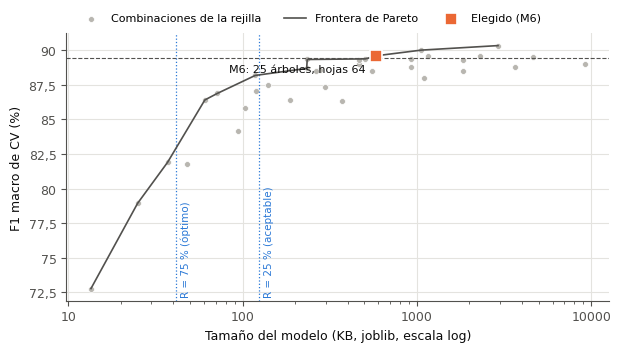

Guardado en /content/drive/MyDrive/Articulo_Grupal_EdgeIIoT/mejoras/M6_compacto


In [ ]:
if correr('M6'):
    filas = []
    for r in REPS:
        F = FICHAS_M6[r]; t = {x['Indicador (unidad)']: x for x in F['tabla_14_3']}; e = F['seleccion']['eleccion']
        tz, cm_ = F['tamanos'], F['runtime_comun']
        cot = {k: pd.DataFrame(v) for k, v in F['cota_retardo'].items()}
        filas.append({'rep': r, 'arboles': e['arboles'], 'hojas_max': e['hojas_max'], 'nodos': F['finales']['nodos'],
                      'profundidad_max': F['finales']['profundidad_max'], 'f1_cv': e['f1_macro_cv'],
                      'f1_m6': t['Puntaje F1 macro (%)']['O2 RF'], 'f1_tcn': t['Puntaje F1 macro (%)']['O1 TCN'],
                      'f1_v1': leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))['rf']['f1_macro'],
                      'tfp_m6': t['Proporción de falsas alarmas, TFP (%)']['O2 RF'],
                      'joblib_m6_kb': tz['rf']['joblib_kb'], 'keras_tcn_kb': tz['tcn']['keras_kb'],
                      'c3_m6_kb': tz['rf']['joblib_c3_kb'], 'onnx_m6_kb': tz['rf']['onnx_kb'], 'onnx_tcn_kb': tz['tcn']['onnx_kb'],
                      'onnxgz_m6_kb': tz['rf']['onnx_gzip_kb'], 'onnxgz_tcn_kb': tz['tcn']['onnx_gzip_kb'],
                      'mem_m6_mb': t['Pico de memoria RAM (MB)']['O2 RF'], 'mem_tcn_mb': t['Pico de memoria RAM (MB)']['O1 TCN'],
                      'memtot_onnx_m6_mb': cm_['rf']['memoria_total_mb'], 'memtot_onnx_tcn_mb': cm_['tcn']['memoria_total_mb'],
                      'lat1024_m6_ms': t['Latencia de inferencia (ms/muestra)']['O2 RF'], 'lat1024_tcn_ms': t['Latencia de inferencia (ms/muestra)']['O1 TCN'],
                      'lote1_m6_ms': cm_['rf']['lote1_mediana_ms'], 'lote1_tcn_ms': cm_['tcn']['lote1_mediana_ms'],
                      'resp_m6_ms': cm_['rf']['respuesta_mediana_ms'], 'resp_tcn_ms': cm_['tcn']['respuesta_mediana_ms'],
                      'flujos_peor_caso_m6': int(cot['rf']['M_c'].max()), 'flujos_peor_caso_tcn': int(cot['tcn']['M_c'].max()),
                      'aceptable_desc': e.get('mejor_aceptable_en_joblib'), 'atributos': ', '.join(F['seleccion']['atributos_k'])})
    M6 = pd.DataFrame(filas).set_index('rep')
    display(M6.drop(columns=['atributos', 'aceptable_desc']).round(4))

    # F1 (bilaterales, Holm sobre 3)
    a1 = pd.DataFrame(leer_json(os.path.join(DIR_M2, 'M2_resultados.json'))['por_rep']).query("brazo == 'A1'").set_index('rep')['f1_macro']
    PR_F1 = pd.DataFrame([{'comparación': 'M6 − v1 (F1 macro)', **prueba_pareada(M6['f1_v1'], M6['f1_m6'], 'two-sided')},
                          {'comparación': 'M6 − TCN (F1 macro)', **prueba_pareada(M6['f1_tcn'], M6['f1_m6'], 'two-sided')},
                          {'comparación': 'M6 − A1 (18 atributos de Gao; igual k)', **prueba_pareada(a1.loc[REPS], M6['f1_m6'], 'two-sided')}])
    PR_F1['p_holm'] = holm(PR_F1['p'])
    display(PR_F1[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p', 'p_holm']])

    # Costos (unilaterales: M6 menor que la TCN; Holm sobre la familia)
    COSTOS = [('Tamaño: joblib vs .keras (KB)', 'keras_tcn_kb', 'joblib_m6_kb'), ('Tamaño: ONNX vs ONNX (KB)', 'onnx_tcn_kb', 'onnx_m6_kb'),
              ('Tamaño: ONNX gzip vs ONNX gzip (KB)', 'onnxgz_tcn_kb', 'onnxgz_m6_kb'), ('Memoria pico, def. v1 (MB)', 'mem_tcn_mb', 'mem_m6_mb'),
              ('Memoria total, ONNX (MB)', 'memtot_onnx_tcn_mb', 'memtot_onnx_m6_mb'), ('Latencia, lote de 1 024 (ms)', 'lat1024_tcn_ms', 'lat1024_m6_ms'),
              ('Latencia, lote de 1, ONNX (ms)', 'lote1_tcn_ms', 'lote1_m6_ms'), ('Tiempo de respuesta por flujo, ONNX (ms)', 'resp_tcn_ms', 'resp_m6_ms')]
    PR_C = pd.DataFrame([{'indicador': n, **prueba_pareada(M6[a], M6[b], 'less')} for n, a, b in COSTOS])
    PR_C['p_holm'] = holm(PR_C['p'])
    PR_C['R_%'] = [(M6[a].mean() - M6[b].mean()) / M6[a].mean() * 100 for _, a, b in COSTOS]
    PR_C['nivel'] = [nivel_R(x) if i < 5 else '—' for i, x in enumerate(PR_C['R_%'])]
    PR_C['M6_menor'] = PR_C['p_holm'] < ALFA
    display(PR_C[['indicador', 'media_O1', 'media_O2', 'R_%', 'nivel', 'prueba', 'p', 'p_holm', 'M6_menor']].rename(
        columns={'media_O1': 'TCN', 'media_O2': 'M6'}))
    R_ATR = (len(ATRIBUTOS) - M6_K) / len(ATRIBUTOS) * 100
    print(f'Atributos: {M6_K} de {len(ATRIBUTOS)} → R = {R_ATR:.2f} % ({nivel_R(R_ATR)}); igual que la TCN (18).')
    desc = pd.DataFrame([dict(rep=r, **(M6.loc[r, 'aceptable_desc'] or {})) for r in REPS])
    print('Descriptivo — mejor configuración de la rejilla que llegaría a «aceptable» en joblib (≤ 75 % del .keras):')
    display(desc.round(3))
    mostrar_consolidado(C_M6, 'Consolidación M6 (tabla 14.6 y veredictos con MI-LiteRF compacto)')
    print('⚠️ Si la TFP sale con «Óptimo» y un porcentaje enorme, es la división entre ≈ 0 (igual que en v2): no reportarlo.')

    # Figura M6 — Pareto de la CV (primera REP) con los umbrales de tamaño frente al .keras de la TCN
    r0 = REPS[0]
    tabla = pd.read_csv(os.path.join(DIR_M6, 'corridas', f'REP-{r0:02d}', 'cv_m6.csv'))
    kb_tcn = M6.loc[r0, 'keras_tcn_kb']
    fig, ax = plt.subplots(figsize=(6.3, 3.6))
    ax.scatter(tabla['tamano_kb'], tabla['f1_macro_cv'], s=18, color='#b8b6b0', edgecolors='white', linewidths=0.5, zorder=2, label='Combinaciones de la rejilla')
    fr = tabla.sort_values('tamano_kb'); fr = fr[fr['f1_macro_cv'] >= fr['f1_macro_cv'].cummax()]
    ax.plot(fr['tamano_kb'], fr['f1_macro_cv'], color=TINTA2, lw=1.2, zorder=3, label='Frontera de Pareto')
    ax.axhline(tabla['f1_macro_cv'].max() * M6_TOLERANCIA, color=TINTA2, lw=0.8, ls='--')
    for R_, txt in [(25, 'R = 25 % (aceptable)'), (75, 'R = 75 % (óptimo)')]:
        xk = kb_tcn * (1 - R_ / 100); ax.axvline(xk, color=COLOR['tcn'], lw=0.9, ls=':')
        ax.annotate(txt, (xk, ax.get_ylim()[0]), xytext=(3, 4), textcoords='offset points', fontsize=7.5, color=COLOR['tcn'], rotation=90)
    el = tabla[tabla['elegido']].iloc[0]
    ax.scatter(el['tamano_kb'], el['f1_macro_cv'], s=70, marker='s', color=COLOR['rf'], edgecolors='white', linewidths=1.2, zorder=4, label='Elegido (M6)')
    ax.annotate(f"M6: {int(el.arboles)} árboles, hojas {int(el.hojas_max) if el.hojas_max else 'sin límite'}", (el['tamano_kb'], el['f1_macro_cv']),
                xytext=(-8, -12), textcoords='offset points', fontsize=8, color=TINTA, ha='right')
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(coma); ax.yaxis.set_major_formatter(coma)
    ax.set_xlabel('Tamaño del modelo (KB, joblib, escala log)'); ax.set_ylabel('F1 macro de CV (%)')
    ax.spines[['top', 'right']].set_visible(False); ax.grid(color=REJILLA, lw=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.45, 1.0), fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(DIR_M6, 'fig_M6_pareto.png'), dpi=200); plt.show()

    with pd.ExcelWriter(os.path.join(DIR_M6, 'M6_resumen.xlsx')) as xw:
        M6.drop(columns=['aceptable_desc']).to_excel(xw, sheet_name='Por REP')
        PR_F1.astype({'ic95_d': str}).to_excel(xw, sheet_name='F1 (Holm)', index=False)
        PR_C.astype({'ic95_d': str}).to_excel(xw, sheet_name='Costos (Holm)', index=False)
        desc.to_excel(xw, sheet_name='Descriptivo aceptable', index=False)
        tabla.to_excel(xw, sheet_name=f'CV REP-{r0:02d}', index=False)
    guardar_json({'regla': texto_regla_m6(), 'por_rep': M6.reset_index().to_dict('records'), 'pruebas_f1': PR_F1.to_dict('records'),
                  'pruebas_costos': PR_C.to_dict('records'), 'atributos_R_%': R_ATR, 'descriptivo_aceptable': desc.to_dict('records')},
                 os.path.join(DIR_M6, 'M6_resultados.json'))
    print('Guardado en', DIR_M6)

## M4. Sensibilidad al artefacto «0»/«0.0» (RF y XGB sin el artefacto; TCN de v1)
Código de S11b **sin cambios** (`M4_CONFIG = 'v1'`: mismos k, T e hiperparámetros de v1). Se unifica «0.0» → «0» en los 7 categóricos **después** de quitar duplicados, de modo que las filas y la división son las de v1; se recalcula la IM y se reentrenan MI-LiteRF y MI-LiteXGB. La comparación es contra la **TCN v1, que conserva el artefacto**, así que es conservadora. Al final se agrega la **cota del retardo de M7** para el RF sin artefacto: muestra cuánto depende «temprana» del artefacto.

In [ ]:
DIR_M4 = os.path.join(DIR_MEJ, 'M4_sin_artefacto')
_BASE_U = {}

def base_unificada():
    if not _BASE_U:
        B = preprocesar(unificar_ceros=True)
        assert np.array_equal(B.y, Y), 'Las filas cambiaron al unificar: no debería pasar'
        _BASE_U['B'] = B
    return _BASE_U['B']

def m4_rep(r):
    dir_r = os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}')
    ruta_ficha = os.path.join(dir_r, f'ficha_REP-{r:02d}.json')
    if hay(ruta_ficha):
        return leer_json(ruta_ficha)
    t_ini = time.time(); os.makedirs(dir_r, exist_ok=True)
    BU = base_unificada()
    D, V = dividir(r), v1(r)
    verificar_v1(D, V)
    DU = dividir(r, BU)
    assert np.array_equal(DU.idx_te, D.idx_te), 'La división no coincide con v1'
    tmp = os.path.join(DIR_TMP, 'M4', D.codigo); os.makedirs(tmp, exist_ok=True)
    # Configuración
    if M4_CONFIG == 'v2':
        e = leer_json(os.path.join(DIR_M3, 'corridas', f'REP-{r:02d}', 'seleccion_m3.json'))
        K, T, RF = e['k'], M3_T, (e['arboles'], e['profundidad'])
        su = M3_FILTRO_SU
    else:
        K, T, RF, su = V.K, V.T, V.rf, False
    t_cv = time.perf_counter()
    rank, orden = ranking_im(DU, BU.ATRIBUTOS, su=su)
    t_mi = time.perf_counter() - t_cv
    rank.to_csv(os.path.join(dir_r, 'mi_ranking.csv'), index=False)
    cols = orden[:K]
    t0 = time.perf_counter()
    Xb, yb = balancear(DU.Xtr[:, cols], DU.ytr, T, D.semilla)
    t_bal = time.perf_counter() - t0
    rf = RandomForestClassifier(RF[0], max_depth=RF[1], n_jobs=-1, random_state=D.semilla)
    xg = XGBClassifier(n_estimators=V.xgb[0], max_depth=V.xgb[1], learning_rate=V.xgb_lr, tree_method='hist', device='cpu',
                       n_jobs=-1, random_state=D.semilla, eval_metric='mlogloss')
    tiempos_ent = {}
    for nombre, modelo in [('rf', rf), ('xgb', xg)]:
        t0 = time.perf_counter(); modelo.fit(Xb, yb); tiempos_ent[nombre] = time.perf_counter() - t0
    ruta_rf, ruta_xgb = os.path.join(dir_r, 'rf.joblib'), os.path.join(dir_r, 'xgb.joblib')
    joblib.dump(rf, ruta_rf); joblib.dump(xg, ruta_xgb)
    finales = {'flujos_entrenamiento_balanceado': int(len(yb)), 'tiempo_balanceo_s': round(t_bal, 1), 'xgb_device': 'cpu'}
    del Xb, yb, rf, xg
    res = medir_ficha(D, V, tmp, dir_r, ruta_rf, DU.Xte[:, cols], ruta_xgb, DU.Xte[:, cols])
    sel = {'k': int(K), 'T': int(T), 'rf_arboles': int(RF[0]), 'rf_profundidad': int(RF[1]), 'xgb_arboles': V.xgb[0],
           'xgb_profundidad': V.xgb[1], 'xgb_lr': V.xgb_lr, 'atributos_k': [BU.ATRIBUTOS[j] for j in cols],
           'tiempo_cv_s': round(t_mi, 1), 'config': M4_CONFIG, 'filtro_su': su}
    tiempos = {'entrenamiento_tcn_min': V.ficha['tiempos']['entrenamiento_tcn_min'], 'validacion_cruzada_min': t_mi / 60,
               'entrenamiento_rf_s': tiempos_ent['rf'], 'entrenamiento_xgb_s': tiempos_ent['xgb']}
    ficha = construir_ficha(D, V, res, {'tcn': len(IDX_GAO), 'rf': int(K), 'xgb': int(K)}, sel, finales, tiempos,
                            f'M4: sin artefacto «0»/«0.0» (config {M4_CONFIG})', BU.preproc, len(BU.ATRIBUTOS))
    ficha['control'] = {'tcn_f1_igual_v1': abs(res['tcn']['f1_macro'] - V.ind['tcn']['f1_macro']) < 0.01}
    guardar_json(ficha, ruta_ficha)
    bitacora('M4', r, t_ini)
    shutil.rmtree(tmp, ignore_errors=True)
    del D, DU; gc.collect()
    return ficha

In [ ]:
if correr('M4'):
    FICHAS_M4 = {}
    for r in REPS:
        t0 = time.time()
        FICHAS_M4[r] = m4_rep(r)
        t = {x['Indicador (unidad)']: x for x in FICHAS_M4[r]['tabla_14_3']}
        print(f"REP-{r:02d} | F1: TCN v1 {t['Puntaje F1 macro (%)']['O1 TCN']:.2f} · RF sin artefacto {t['Puntaje F1 macro (%)']['O2 RF']:.2f} · "
              f"XGB sin artefacto {t['Puntaje F1 macro (%)']['O2 XGBoost']:.2f} | TFP RF {t['Proporción de falsas alarmas, TFP (%)']['O2 RF']:.4f} % | "
              f"{time.time() - t0:.0f} s")
    C_M4 = consolidar(DIR_M4, 'M4_sin_artefacto')
    filas = []
    for r in REPS:
        t = {x['Indicador (unidad)']: x for x in FICHAS_M4[r]['tabla_14_3']}
        filas.append({'rep': r, 'f1_tcn_v1': t['Puntaje F1 macro (%)']['O1 TCN'], 'f1_rf_sin_art': t['Puntaje F1 macro (%)']['O2 RF'],
                      'f1_rf_v1': leer_json(os.path.join(DIR_V1, f'REP-{r:02d}', 'indicadores.json'))['rf']['f1_macro'],
                      'tfp_tcn': t['Proporción de falsas alarmas, TFP (%)']['O1 TCN'], 'tfp_rf_sin_art': t['Proporción de falsas alarmas, TFP (%)']['O2 RF'],
                      'atributos': ', '.join(FICHAS_M4[r]['seleccion']['atributos_k'])})
    M4 = pd.DataFrame(filas).set_index('rep')
    display(M4.drop(columns='atributos').round(4))
    pr = [{'comparación': 'RF sin artefacto > TCN v1 (F1)', **prueba_pareada(M4['f1_tcn_v1'], M4['f1_rf_sin_art'], 'greater')},
          {'comparación': 'RF sin artefacto − RF v1 (F1)', **prueba_pareada(M4['f1_rf_v1'], M4['f1_rf_sin_art'], 'two-sided')}]
    PR_M4 = pd.DataFrame(pr)
    display(PR_M4[['comparación', 'media_O1', 'media_O2', 'media_d', 'ic95_d', 'prueba', 'p']])
    mostrar_consolidado(C_M4, 'Consolidación M4 (sin artefacto)')
    guardar_json({'por_rep': M4.reset_index().to_dict('records'), 'comparaciones': PR_M4.to_dict('records'), 'config': M4_CONFIG},
                 os.path.join(DIR_M4, 'M4_resultados.json'))

Unificado «0»/«0.0»: 1,909,671 flujos | 88 dimensiones | 23 s
REP-01 | F1: TCN v1 68.46 · RF sin artefacto 75.57 · XGB sin artefacto 80.36 | TFP RF 12.4697 % | 58 s
REP-02 | F1: TCN v1 68.94 · RF sin artefacto 74.85 · XGB sin artefacto 78.10 | TFP RF 12.0198 % | 34 s
REP-03 | F1: TCN v1 69.86 · RF sin artefacto 76.06 · XGB sin artefacto 82.44 | TFP RF 13.5415 % | 36 s
REP-04 | F1: TCN v1 68.31 · RF sin artefacto 77.60 · XGB sin artefacto 80.41 | TFP RF 9.3622 % | 35 s
REP-05 | F1: TCN v1 68.81 · RF sin artefacto 74.46 · XGB sin artefacto 79.99 | TFP RF 13.7261 % | 35 s
REP-06 | F1: TCN v1 68.88 · RF sin artefacto 76.38 · XGB sin artefacto 79.08 | TFP RF 14.3055 % | 36 s
REP-07 | F1: TCN v1 68.38 · RF sin artefacto 75.66 · XGB sin artefacto 79.12 | TFP RF 15.7001 % | 35 s
REP-08 | F1: TCN v1 66.93 · RF sin artefacto 74.31 · XGB sin artefacto 81.11 | TFP RF 14.2595 % | 35 s
REP-09 | F1: TCN v1 68.50 · RF sin artefacto 74.64 · XGB sin artefacto 80.97 | TFP RF 15.2363 % | 35 s
REP-10 | F1:

,f1_tcn_v1,f1_rf_sin_art,f1_rf_v1,tfp_tcn,tfp_rf_sin_art
rep,,,,,
1,68.4550,75.5683,90.0906,0.0000,12.4697
2,68.9383,74.8531,90.5039,0.0000,12.0198
3,69.8563,76.0590,90.3179,0.0000,13.5415
4,68.3053,77.6039,90.4694,0.0000,9.3622
5,68.8086,74.4633,90.2995,0.0000,13.7261
6,68.8768,76.3819,90.3156,0.0005,14.3055
7,68.3797,75.6553,90.3109,0.0000,15.7001
8,66.9260,74.3077,90.2404,0.0000,14.2595
9,68.4976,74.6381,90.2469,0.0000,15.2363


,comparación,media_O1,media_O2,media_d,ic95_d,prueba,p
0,RF sin artefacto > TCN v1 (F1),68.529980,75.338817,6.808836,"(5.992298654831058, 7.625374280563958)",t pareada,7.601165e-09
1,RF sin artefacto − RF v1 (F1),90.317407,75.338817,-14.978590,"(-15.778830726428266, -14.178350194693694)",t pareada,1.140287e-11


— Consolidación M4 (sin artefacto) —


,Hipótesis,Veredicto,Sustento
0,H.E. 1 (exactitud: F1 macro),Respaldada,"t pareada, p Holm = < 0,001"
1,H.E. 2 (latencia de detección: inferencia y re...,No respaldada,"Latencia: No respaldada (t pareada, p Holm = 1..."
2,H.E. 3 (TFP),No respaldada,"t pareada, p Holm = 1,000"
3,H.G. (detección temprana de anomalías),No respaldada,Requiere las tres específicas; se sostienen: H...


,Indicador (unidad),tcn_media,rf_media,xgb_media,valor_pct,nivel_RF
0,Pico de memoria RAM (MB),122.3109,4.8039,5.4477,9.607240e+01,Óptimo
1,Tamaño del modelo serializado (KB),166.4492,3437.5072,870.2432,-1.965199e+03,Crítico
2,Número de atributos (n.º),18.0000,25.0000,25.0000,7.159090e+01,Aceptable
3,Puntaje F1 macro (%),68.5300,75.3388,80.3296,9.935600e+00,Aceptable
4,Latencia de inferencia (ms/muestra),0.0017,0.0035,0.0069,1.088199e+02,Óptimo
5,Retardo de detección (ms; mediana),NaN,NaN,NaN,NaN,No calculable
6,"Proporción de falsas alarmas, TFP (%)",0.0000,13.5192,16.0773,2.766020e+07,Crítico


In [ ]:
if correr('M4'):
    filas = []
    for r in REPS:
        pred = np.load(os.path.join(DIR_M4, 'corridas', f'REP-{r:02d}', 'medicion_rf_pred.npy')).astype(np.int64)
        tab = cota_retardo(confusion_matrix(yte_rep(r), pred, labels=range(N_CLASES)))
        filas.append({'rep': r, **resumen_cota(tab)})
    COTA_M4 = pd.DataFrame(filas).set_index('rep')
    print('Cota del retardo (M7) para MI-LiteRF SIN artefacto:')
    display(COTA_M4.round(3))
    R_ = leer_json(os.path.join(DIR_M4, 'M4_resultados.json'))
    R_['cota_retardo_rf_sin_artefacto'] = COTA_M4.reset_index().to_dict('records')
    guardar_json(R_, os.path.join(DIR_M4, 'M4_resultados.json'))
    print('Agregado a M4_resultados.json')

Cota del retardo (M7) para MI-LiteRF SIN artefacto:


,flujos_peor_caso_media,flujos_peor_caso_max,flujos_esperado_media,clases_con_fallos,flujos_ataque_como_normal
rep,,,,,
1,168.571,751,0.015,7,2360
2,206.857,959,0.018,7,2896
3,130.071,623,0.011,8,1821
4,324.500,1430,0.030,10,4543
5,129.429,591,0.011,8,1812
6,112.857,644,0.009,9,1580
7,18.857,141,0.001,9,264
8,92.500,374,0.008,8,1295
9,65.357,318,0.005,9,915


Agregado a M4_resultados.json


## Resumen S11c: hasta dónde se sostiene el título
Junta M7, M6 y M4 en `mejoras/S11c_resumen.json`. Las decisiones (operacionalización de «temprana», definición de «ligero», TFP descriptiva) se toman con Ricardo y el profesor; este cuadro solo reúne la evidencia.

In [ ]:
resumen = {'generado': datetime.datetime.now().strftime('%d/%m/%Y %H:%M'), 'reps': REPS}
ruta = os.path.join(DIR_MEJ, 'M7_retardo', 'M7_resultados.json')
if os.path.exists(ruta):
    R_ = leer_json(ruta); d = pd.DataFrame(R_['por_rep'])
    resumen['M7'] = {'veredicto': R_['veredicto'],
                     'pruebas': [{k: x[k] for k in ('componente', 'media_O1', 'media_O2', 'p_holm')} for x in R_['pruebas']],
                     'flujos_ataque_como_normal': d.groupby('modelo')['flujos_ataque_como_normal'].agg(['mean', 'max']).to_dict()}
ruta = os.path.join(DIR_MEJ, 'M6_compacto', 'M6_resultados.json')
if os.path.exists(ruta):
    R_ = leer_json(ruta); d = pd.DataFrame(R_['por_rep'])
    resumen['M6'] = {**{c: [float(d[c].mean()), float(d[c].std(ddof=1)) if len(d) > 1 else None]
                        for c in ['f1_m6', 'f1_tcn', 'joblib_m6_kb', 'c3_m6_kb', 'onnx_m6_kb', 'onnxgz_m6_kb', 'nodos',
                                  'mem_m6_mb', 'lat1024_m6_ms', 'lat1024_tcn_ms', 'lote1_m6_ms', 'resp_m6_ms']},
                     'atributos_R_%': R_['atributos_R_%'],
                     'pruebas_f1': [{k: x[k] for k in ('comparación', 'media_d', 'p_holm')} for x in R_['pruebas_f1']],
                     'pruebas_costos': [{k: x[k] for k in ('indicador', 'media_O1', 'media_O2', 'R_%', 'nivel', 'p_holm')} for x in R_['pruebas_costos']]}
ruta = os.path.join(DIR_MEJ, 'M4_sin_artefacto', 'M4_resultados.json')
if os.path.exists(ruta):
    R_ = leer_json(ruta); d = pd.DataFrame(R_['por_rep'])
    resumen['M4'] = {c: [float(d[c].mean()), float(d[c].std(ddof=1)) if len(d) > 1 else None]
                     for c in ['f1_tcn_v1', 'f1_rf_sin_art', 'f1_rf_v1', 'tfp_tcn', 'tfp_rf_sin_art']}
    resumen['M4']['comparaciones'] = [{k: x[k] for k in ('comparación', 'media_d', 'p')} for x in R_['comparaciones']]
    if 'cota_retardo_rf_sin_artefacto' in R_:
        c = pd.DataFrame(R_['cota_retardo_rf_sin_artefacto'])
        resumen['M4']['cota_rf_sin_artefacto'] = {'flujos_ataque_como_normal_media': float(c['flujos_ataque_como_normal'].mean()),
                                                  'flujos_peor_caso_max_media': float(c['flujos_peor_caso_max'].mean())}
guardar_json(resumen, os.path.join(DIR_MEJ, 'S11c_resumen.json'))
print(json.dumps(resumen, ensure_ascii=False, indent=1, default=str))

{
 "generado": "18/11/2026 17:53",
 "reps": [
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10
 ],
 "M7": {
  "veredicto": {
   "H.E. 2 (versión 2)": "Respaldada",
   "retardo": "RD = t_resp: TCN y MI-LiteRF alarman en el primer flujo de todo episodio, con cualquier orden (10 REP)",
   "(b1) MI-LiteRF necesita más flujos que la TCN": false
  },
  "pruebas": [
   {
    "componente": "(a) latencia por flujo, lote de 1 (ms)",
    "media_O1": 0.0483951,
    "media_O2": 0.0104292,
    "p_holm": 1.9957372922975725e-13
   },
   {
    "componente": "(b2) tiempo de respuesta por flujo, t_resp (ms)",
    "media_O1": 0.0632961,
    "media_O2": 0.01913,
    "p_holm": 3.087216975927366e-13
   }
  ],
  "flujos_ataque_como_normal": {
   "mean": {
    "rf": 0.0,
    "tcn": 0.0,
    "xgb": 0.0
   },
   "max": {
    "rf": 0,
    "tcn": 0,
    "xgb": 0
   }
  }
 },
 "M6": {
  "f1_m6": [
   87.3088681974987,
   1.6143310698897955
  ],
  "f1_tcn": [
   68.5299804531817,
   0.7341703819981483
  ],
  "jobli

In [ ]:
# (Opcional) Exportar este cuaderno a HTML y descargarlo
import subprocess
from google.colab import files
ruta_ipynb = '/content/drive/MyDrive/Colab Notebooks/S11c_Mejoras2.ipynb'
ruta_html = '/content/S11c_Mejoras2.html'
subprocess.run(['jupyter', 'nbconvert', '--to', 'html', ruta_ipynb, '--output', ruta_html], check=True)
files.download(ruta_html)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>